<a href="https://colab.research.google.com/github/nehashanmugam028-lab/Ultrasonic-glasses-for-the-disabled/blob/main/Copy_of_Untitled4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas openpyxl matplotlib seaborn spacy pdfplumber gradio -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 27.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Professional_AI_Resume_Screening_Dataset_10000.xlsx to Professional_AI_Resume_Screening_Dataset_10000.xlsx


In [ ]:
  import pandas as pd

  file_name = "Professional_AI_Resume_Screening_Dataset_10000.xlsx"

  df = pd.read_excel(file_name, engine="openpyxl")

  print("Dataset loaded successfully!")
  print("Number of rows:", df.shape[0])
  print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 10000
Number of columns: 24


In [ ]:
df.head()

,Candidate_ID,Full_Name,Email,Phone,City,Degree,University,CGPA,Experience_Years,Current_Job_Role,...,Internships,Certifications,Languages_Known,Preferred_Location,Expected_Salary_LPA,LinkedIn,GitHub,Resume_Text,AI_Match_Score,Recruiter_Decision
0,1,Candidate_00001,candidate00001@example.com,+91-7999270936,Gurugram,B.Tech,IIT Madras,8.43,8,NLP Engineer,...,Yes - 6 months,TensorFlow Developer,"Kannada, Tamil, English","Kochi, Bengaluru",9,https://linkedin.com/in/candidate00001,https://github.com/candidate00001,Candidate_00001 is a B.Tech graduate with 8 ye...,55,Rejected
1,2,Candidate_00002,candidate00002@example.com,+91-7338444264,Mumbai,M.Sc,IIT Madras,7.28,5,Data Analyst,...,Yes - 6 months,NaN,"Tamil, English, Hindi","Bengaluru, Coimbatore",7,https://linkedin.com/in/candidate00002,https://github.com/candidate00002,Candidate_00002 is a M.Sc graduate with 5 year...,88,Selected
2,3,Candidate_00003,candidate00003@example.com,+91-8629748727,Hyderabad,M.Sc,Delhi University,9.86,10,Business Analyst,...,Yes - 1 year,TensorFlow Developer,"Tamil, English, Hindi","Gurugram, Chennai",22,https://linkedin.com/in/candidate00003,https://github.com/candidate00003,Candidate_00003 is a M.Sc graduate with 10 yea...,91,Selected
3,4,Candidate_00004,candidate00004@example.com,+91-9119634399,Mumbai,M.Sc,VTU,9.00,8,Business Analyst,...,No,TensorFlow Developer,"Kannada, Telugu, Tamil","Gurugram, Kochi",21,https://linkedin.com/in/candidate00004,https://github.com/candidate00004,Candidate_00004 is a M.Sc graduate with 8 year...,84,Shortlisted
4,5,Candidate_00005,candidate00005@example.com,+91-7656439677,Bengaluru,M.Tech,VIT,9.02,2,AI Engineer,...,Yes - 1 year,NaN,"Tamil, Hindi, English","Mumbai, Noida",11,https://linkedin.com/in/candidate00005,https://github.com/candidate00005,Candidate_00005 is a M.Tech graduate with 2 ye...,79,Shortlisted


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Candidate_ID           10000 non-null  int64  
 1   Full_Name              10000 non-null  object 
 2   Email                  10000 non-null  object 
 3   Phone                  10000 non-null  object 
 4   City                   10000 non-null  object 
 5   Degree                 10000 non-null  object 
 6   University             10000 non-null  object 
 7   CGPA                   10000 non-null  float64
 8   Experience_Years       10000 non-null  int64  
 9   Current_Job_Role       10000 non-null  object 
 10  Technical_Skills       10000 non-null  object 
 11  Soft_Skills            10000 non-null  object 
 12  Programming_Languages  10000 non-null  object 
 13  Projects               10000 non-null  object 
 14  Internships            10000 non-null  object 
 15  Cer

In [ ]:
df.isnull().sum()

,0
Candidate_ID,0
Full_Name,0
Email,0
Phone,0
City,0
Degree,0
University,0
CGPA,0
Experience_Years,0
Current_Job_Role,0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Duplicate Candidate IDs:", df["Candidate_ID"].duplicated().sum())

Duplicate Candidate IDs: 0


In [ ]:
missing_values = df.isnull().sum()

print(missing_values)

Candidate_ID                0
Full_Name                   0
Email                       0
Phone                       0
City                        0
Degree                      0
University                  0
CGPA                        0
Experience_Years            0
Current_Job_Role            0
Technical_Skills            0
Soft_Skills                 0
Programming_Languages       0
Projects                    0
Internships                 0
Certifications           1394
Languages_Known             0
Preferred_Location          0
Expected_Salary_LPA         0
LinkedIn                    0
GitHub                      0
Resume_Text                 0
AI_Match_Score              0
Recruiter_Decision          0
dtype: int64


In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Candidate_ID', 'Full_Name', 'Email', 'Phone', 'City', 'Degree', 'University', 'CGPA', 'Experience_Years', 'Current_Job_Role', 'Technical_Skills', 'Soft_Skills', 'Programming_Languages', 'Projects', 'Internships', 'Certifications', 'Languages_Known', 'Preferred_Location', 'Expected_Salary_LPA', 'LinkedIn', 'GitHub', 'Resume_Text', 'AI_Match_Score', 'Recruiter_Decision']


In [ ]:
df["Technical_Skills"] = (
    df["Technical_Skills"]
    .fillna("")
    .astype(str)
    .str.strip()
)

In [ ]:
print(df["Technical_Skills"].head(10).to_string(index=False))

Java, Git, Kubernetes, Docker, Scikit-learn, Te...
React, Git, Pandas, Azure, FastAPI, TensorFlow,...
Git, Power BI, Django, NumPy, Jenkins, Node.js,...
Azure, Excel, Spring Boot, Power BI, Pandas, Li...
       PyTorch, Jenkins, Git, React, FastAPI, HTML
Deep Learning, FastAPI, Excel, Machine Learning...
SQL, Docker, Machine Learning, C++, React, Jenkins
AWS, Jenkins, PostgreSQL, Scikit-learn, MySQL, ...
Pandas, AWS, HTML, Azure, SQL, Spark, Django, N...
JavaScript, Kubernetes, Linux, Spring Boot, Sci...


In [ ]:
df["Experience_Years"] = pd.to_numeric(
    df["Experience_Years"],
    errors="coerce"
)

print(df["Experience_Years"].dtype)

int64


In [ ]:
df["CGPA"] = pd.to_numeric(
    df["CGPA"],
    errors="coerce"
)

print(df["CGPA"].describe())

count    10000.000000
mean         8.071461
std          1.069981
min          6.200000
25%          7.140000
50%          8.090000
75%          9.000000
max          9.900000
Name: CGPA, dtype: float64


In [ ]:
df = df.dropna(subset=["Candidate_ID"])

df["Candidate_ID"] = df["Candidate_ID"].astype(int)

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Missing Candidate IDs:", df["Candidate_ID"].isnull().sum())

Rows: 10000
Columns: 24
Duplicate rows: 0
Missing Candidate IDs: 0


In [ ]:
job_data = {
    "Job_ID": [
        "J001", "J002", "J003", "J004", "J005",
        "J006", "J007", "J008", "J009", "J010"
    ],

    "Job_Title": [
        "Data Scientist",
        "Machine Learning Engineer",
        "Python Developer",
        "Java Developer",
        "Web Developer",
        "Data Analyst",
        "Cloud Engineer",
        "DevOps Engineer",
        "AI Engineer",
        "Full Stack Developer"
    ],

    "Required_Skills": [
        "Python, SQL, Machine Learning, Pandas, NumPy, Scikit-learn",
        "Python, Machine Learning, Deep Learning, TensorFlow, PyTorch",
        "Python, Django, Flask, FastAPI, SQL, Git",
        "Java, Spring Boot, SQL, Git, Docker",
        "HTML, CSS, JavaScript, React, Git",
        "Python, SQL, Excel, Power BI, Tableau",
        "AWS, Azure, Docker, Kubernetes, Linux",
        "Linux, Docker, Kubernetes, Jenkins, Git, AWS",
        "Python, TensorFlow, PyTorch, NLP, Deep Learning",
        "HTML, CSS, JavaScript, React, Node.js, MongoDB"
    ],

    "Min_Experience": [
        2, 2, 1, 2, 1,
        1, 2, 2, 2, 1
    ],

    "Education": [
        "B.Tech/M.Tech",
        "B.Tech/M.Tech",
        "B.Tech/MCA",
        "B.Tech/MCA",
        "B.Tech/BCA",
        "B.Tech/B.Sc/MCA",
        "B.Tech/M.Tech",
        "B.Tech/MCA",
        "B.Tech/M.Tech",
        "B.Tech/BCA/MCA"
    ]
}

jobs_df = pd.DataFrame(job_data)

print("Job Requirements Dataset Created Successfully!")
print("Number of Jobs:", len(jobs_df))
print("Number of Columns:", len(jobs_df.columns))

Job Requirements Dataset Created Successfully!
Number of Jobs: 10
Number of Columns: 5


In [ ]:
jobs_df

,Job_ID,Job_Title,Required_Skills,Min_Experience,Education
0,J001,Data Scientist,"Python, SQL, Machine Learning, Pandas, NumPy, ...",2,B.Tech/M.Tech
1,J002,Machine Learning Engineer,"Python, Machine Learning, Deep Learning, Tenso...",2,B.Tech/M.Tech
2,J003,Python Developer,"Python, Django, Flask, FastAPI, SQL, Git",1,B.Tech/MCA
3,J004,Java Developer,"Java, Spring Boot, SQL, Git, Docker",2,B.Tech/MCA
4,J005,Web Developer,"HTML, CSS, JavaScript, React, Git",1,B.Tech/BCA
5,J006,Data Analyst,"Python, SQL, Excel, Power BI, Tableau",1,B.Tech/B.Sc/MCA
6,J007,Cloud Engineer,"AWS, Azure, Docker, Kubernetes, Linux",2,B.Tech/M.Tech
7,J008,DevOps Engineer,"Linux, Docker, Kubernetes, Jenkins, Git, AWS",2,B.Tech/MCA
8,J009,AI Engineer,"Python, TensorFlow, PyTorch, NLP, Deep Learning",2,B.Tech/M.Tech
9,J010,Full Stack Developer,"HTML, CSS, JavaScript, React, Node.js, MongoDB",1,B.Tech/BCA/MCA


In [ ]:
job = jobs_df.iloc[0]

print("Job ID:", job["Job_ID"])
print("Job Title:", job["Job_Title"])
print("Required Skills:", job["Required_Skills"])
print("Minimum Experience:", job["Min_Experience"])
print("Education:", job["Education"])

Job ID: J001
Job Title: Data Scientist
Required Skills: Python, SQL, Machine Learning, Pandas, NumPy, Scikit-learn
Minimum Experience: 2
Education: B.Tech/M.Tech


In [ ]:
def get_required_skills(job_id):

    job = jobs_df[jobs_df["Job_ID"] == job_id].iloc[0]

    skills = job["Required_Skills"].split(",")

    skills = [skill.strip().lower() for skill in skills]

    return skills

In [ ]:
skills = get_required_skills("J001")

print(skills)

['python', 'sql', 'machine learning', 'pandas', 'numpy', 'scikit-learn']


In [ ]:
skills = get_required_skills("J007")

print(skills)


['aws', 'azure', 'docker', 'kubernetes', 'linux']


In [ ]:
jobs_df.to_csv("job_requirements.csv", index=False)

print("Job Requirements Dataset saved successfully!")

Job Requirements Dataset saved successfully!


In [ ]:
class AVLNode:

    def __init__(self, candidate_id, candidate_data):
        self.candidate_id = candidate_id
        self.candidate_data = candidate_data

        self.left = None
        self.right = None

        self.height = 1


class AVLTree:

    def __init__(self):
        self.root = None

    # Get height of a node
    def get_height(self, node):

        if node is None:
            return 0

        return node.height

    # Calculate balance factor
    def get_balance(self, node):

        if node is None:
            return 0

        return (
            self.get_height(node.left)
            - self.get_height(node.right)
        )

    # Right Rotation
    def right_rotate(self, y):

        x = y.left
        T2 = x.right

        x.right = y
        y.left = T2

        y.height = 1 + max(
            self.get_height(y.left),
            self.get_height(y.right)
        )

        x.height = 1 + max(
            self.get_height(x.left),
            self.get_height(x.right)
        )

        return x

    # Left Rotation
    def left_rotate(self, x):

        y = x.right
        T2 = y.left

        y.left = x
        x.right = T2

        x.height = 1 + max(
            self.get_height(x.left),
            self.get_height(x.right)
        )

        y.height = 1 + max(
            self.get_height(y.left),
            self.get_height(y.right)
        )

        return y

    # Insert a candidate
    def insert(self, node, candidate_id, candidate_data):

        # If tree is empty
        if node is None:
            return AVLNode(candidate_id, candidate_data)

        # Insert into left subtree
        if candidate_id < node.candidate_id:

            node.left = self.insert(
                node.left,
                candidate_id,
                candidate_data
            )

        # Insert into right subtree
        elif candidate_id > node.candidate_id:

            node.right = self.insert(
                node.right,
                candidate_id,
                candidate_data
            )

        # Duplicate ID
        else:
            return node

        # Update height
        node.height = 1 + max(
            self.get_height(node.left),
            self.get_height(node.right)
        )

        # Calculate balance factor
        balance = self.get_balance(node)

        # LL Case
        if balance > 1 and candidate_id < node.left.candidate_id:
            return self.right_rotate(node)

        # RR Case
        if balance < -1 and candidate_id > node.right.candidate_id:
            return self.left_rotate(node)

        # LR Case
        if balance > 1 and candidate_id > node.left.candidate_id:

            node.left = self.left_rotate(node.left)

            return self.right_rotate(node)

        # RL Case
        if balance < -1 and candidate_id < node.right.candidate_id:

            node.right = self.right_rotate(node.right)

            return self.left_rotate(node)

        return node

    # Search for a candidate
    def search(self, node, candidate_id):

        if node is None:
            return None

        if candidate_id == node.candidate_id:
            return node.candidate_data

        if candidate_id < node.candidate_id:
            return self.search(node.left, candidate_id)

        return self.search(node.right, candidate_id)


print("AVL Tree class created successfully!")

AVL Tree class created successfully!


In [ ]:
avl = AVLTree()

print("AVL Tree created successfully!")

AVL Tree created successfully!


In [ ]:
for _, row in df.iterrows():

    candidate_id = int(row["Candidate_ID"])

    candidate_data = {
        "Name": row["Full_Name"],
        "Email": row["Email"],
        "Skills": row["Technical_Skills"],
        "Experience": row["Experience_Years"],
        "Education": row["Degree"],
        "Role": row["Current_Job_Role"]
    }

    avl.root = avl.insert(
        avl.root,
        candidate_id,
        candidate_data
    )

print("All 10,000 candidates inserted into AVL Tree!")

All 10,000 candidates inserted into AVL Tree!


In [ ]:
result = avl.search(avl.root, 5000)

print(result)

{'Name': 'Candidate_05000', 'Email': 'candidate05000@example.com', 'Skills': 'React, Node.js, AWS, C++, MongoDB, Git, Linux, Hadoop', 'Experience': 9, 'Education': 'MCA', 'Role': 'Data Analyst'}


In [ ]:
test_ids = [1, 100, 5000, 7500, 10000]

for candidate_id in test_ids:

    result = avl.search(avl.root, candidate_id)

    if result:
        print(f"Candidate {candidate_id} found")
        print("Name:", result["Name"])
        print("Role:", result["Role"])
        print()
    else:
        print(f"Candidate {candidate_id} not found")

Candidate 1 found
Name: Candidate_00001
Role: NLP Engineer

Candidate 100 found
Name: Candidate_00100
Role: Data Analyst

Candidate 5000 found
Name: Candidate_05000
Role: Data Analyst

Candidate 7500 found
Name: Candidate_07500
Role: NLP Engineer

Candidate 10000 found
Name: Candidate_10000
Role: Business Analyst



In [ ]:
result = avl.search(avl.root, 99999)

print(result)

None


In [ ]:
print(avl.search(avl.root, 1))

{'Name': 'Candidate_00001', 'Email': 'candidate00001@example.com', 'Skills': 'Java, Git, Kubernetes, Docker, Scikit-learn, TensorFlow', 'Experience': 8, 'Education': 'B.Tech', 'Role': 'NLP Engineer'}


In [ ]:
print(avl.search(avl.root, 5000))

{'Name': 'Candidate_05000', 'Email': 'candidate05000@example.com', 'Skills': 'React, Node.js, AWS, C++, MongoDB, Git, Linux, Hadoop', 'Experience': 9, 'Education': 'MCA', 'Role': 'Data Analyst'}


In [ ]:
print(avl.search(avl.root, 10000))

{'Name': 'Candidate_10000', 'Email': 'candidate10000@example.com', 'Skills': 'Tableau, Kubernetes, Scikit-learn, PyTorch, Pandas, TensorFlow, Spark, Django', 'Experience': 0, 'Education': 'M.Tech', 'Role': 'Business Analyst'}


In [ ]:
print(avl.search(avl.root, 99999))

None


In [ ]:
print("AVL Tree Height:", avl.get_height(avl.root))
#END .................................................................................................

AVL Tree Height: 14


In [ ]:
#neha

In [ ]:
def check_avl_balance(node):

    if node is None:
        return True

    balance = avl.get_balance(node)

    # AVL balance condition
    if balance < -1 or balance > 1:
        return False

    return (
        check_avl_balance(node.left)
        and check_avl_balance(node.right)
    )


is_balanced = check_avl_balance(avl.root)

print("Is AVL Tree Balanced?", is_balanced)

Is AVL Tree Balanced? True


In [ ]:
def linear_search(candidate_id):

    for _, row in df.iterrows():

        if int(row["Candidate_ID"]) == candidate_id:
            return row

    return None

In [ ]:
import time

start = time.perf_counter()

linear_result = linear_search(9000)

linear_time = time.perf_counter() - start

print("Linear Search Time:", linear_time)

Linear Search Time: 0.3882934139999179


In [ ]:
start = time.perf_counter()

avl_result = avl.search(avl.root, 9000)

avl_time = time.perf_counter() - start

print("AVL Search Time:", avl_time)

AVL Search Time: 0.00022515199998451862


In [ ]:
import random
import time

test_ids = random.sample(range(1, 10001), 100)

# Linear Search
start = time.perf_counter()

for candidate_id in test_ids:
    linear_search(candidate_id)

linear_total_time = time.perf_counter() - start


# AVL Search
start = time.perf_counter()

for candidate_id in test_ids:
    avl.search(avl.root, candidate_id)

avl_total_time = time.perf_counter() - start


print("Number of searches:", len(test_ids))
print("Linear Search Total Time:", linear_total_time)
print("AVL Search Total Time:", avl_total_time)

Number of searches: 100
Linear Search Total Time: 22.71632823599998
AVL Search Total Time: 0.0003771379999761848


In [ ]:
if avl_total_time > 0:

    speedup = linear_total_time / avl_total_time

    print("AVL Speedup:", speedup, "times")

else:

    print("AVL search time too small to calculate speedup.")

AVL Speedup: 60233.46424235811 times


In [ ]:
candidate_id = 5000

linear_result = linear_search(candidate_id)
avl_result = avl.search(avl.root, candidate_id)

print("Linear Search Candidate:")
print(linear_result["Full_Name"])

print("\nAVL Search Candidate:")
print(avl_result["Name"])

Linear Search Candidate:
Candidate_05000

AVL Search Candidate:
Candidate_05000


In [ ]:
performance_df = pd.DataFrame({
    "Method": [
        "Linear Search",
        "AVL Tree Search"
    ],

    "Time": [
        linear_total_time,
        avl_total_time
    ],

    "Complexity": [
        "O(n)",
        "O(log n)"-
    ]
})

performance_df

,Method,Time,Complexity
0,Linear Search,22.716328,O(n)
1,AVL Tree Search,0.000377,O(log n)


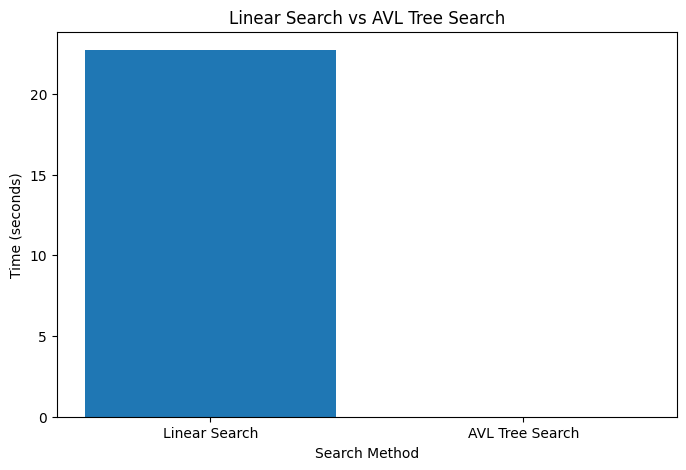

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    performance_df["Method"],
    performance_df["Time"]
)

plt.title("Linear Search vs AVL Tree Search")
plt.xlabel("Search Method")
plt.ylabel("Time (seconds)")

plt.show()

In [ ]:
all_skills = set()

for skills_text in df["Technical_Skills"]:

    skills = skills_text.split(",")

    for skill in skills:
        skill = skill.strip().lower()

        if skill:
            all_skills.add(skill)

print("Total unique skills:", len(all_skills))

Total unique skills: 37


In [ ]:
sorted(list(all_skills))[:30]

['aws',
 'azure',
 'c++',
 'css',
 'deep learning',
 'django',
 'docker',
 'excel',
 'fastapi',
 'flask',
 'git',
 'hadoop',
 'html',
 'java',
 'javascript',
 'jenkins',
 'kubernetes',
 'linux',
 'machine learning',
 'mongodb',
 'mysql',
 'nlp',
 'node.js',
 'numpy',
 'pandas',
 'postgresql',
 'power bi',
 'python',
 'pytorch',
 'react']

In [ ]:
#prathibaa

In [ ]:
class TrieNode:

    def __init__(self):

        self.children = {}

        self.is_end_of_word = False

In [ ]:
class Trie:

    def __init__(self):

        self.root = TrieNode()

In [ ]:
    def insert(self, word):

        current = self.root

        for char in word:

            if char not in current.children:

                current.children[char] = TrieNode()

            current = current.children[char]

        current.is_end_of_word = True

In [ ]:
is_end_of_word = True

In [ ]:
def search(self, word):

        current = self.root

        for char in word:

            if char not in current.children:

                return False

            current = current.children[char]

        return current.is_end_of_word

In [ ]:
    def starts_with(self, prefix):

        current = self.root

        for char in prefix:

            if char not in current.children:

                return False

            current = current.children[char]

        return True

In [ ]:
class TrieNode:

    def __init__(self):

        self.children = {}

        self.is_end_of_word = False


class Trie:

    def __init__(self):

        self.root = TrieNode()

    # Insert a skill
    def insert(self, word):

        current = self.root

        for char in word:

            if char not in current.children:

                current.children[char] = TrieNode()

            current = current.children[char]

        current.is_end_of_word = True

    # Search for an exact skill
    def search(self, word):

        current = self.root

        for char in word:

            if char not in current.children:

                return False

            current = current.children[char]

        return current.is_end_of_word

    # Check whether a prefix exists
    def starts_with(self, prefix):

        current = self.root

        for char in prefix:

            if char not in current.children:

                return False

            current = current.children[char]

        return True


print("Trie class created successfully!")

Trie class created successfully!


In [ ]:
trie = Trie()

print("Trie created successfully!")

Trie created successfully!


In [ ]:
for skill in all_skills:

    trie.insert(skill)

print("All skills inserted into Trie!")

All skills inserted into Trie!


In [ ]:
print("Python:", trie.search("python"))
print("Machine Learning:", trie.search("machine learning"))
print("Docker:", trie.search("docker"))
print("Blockchain:", trie.search("blockchain"))

Python: True
Machine Learning: True
Docker: True
Blockchain: False


In [ ]:
print("Prefix 'py':", trie.starts_with("py"))
print("Prefix 'mach':", trie.starts_with("mach"))
print("Prefix 'xyz':", trie.starts_with("xyz"))

Prefix 'py': True
Prefix 'mach': True
Prefix 'xyz': False


In [ ]:
def get_candidate_skills(candidate_id):

    candidate = avl.search(avl.root, candidate_id)

    if candidate is None:
        return []

    skills = candidate["Skills"].split(",")

    skills = [
        skill.strip().lower()
        for skill in skills
        if skill.strip()
    ]

    return skills

In [ ]:
get_candidate_skills(5000)

['react', 'node.js', 'aws', 'c++', 'mongodb', 'git', 'linux', 'hadoop']

In [ ]:
candidate_skills = get_candidate_skills(5000)

print("Candidate 5000 Skills:")
print(candidate_skills)

Candidate 5000 Skills:
['react', 'node.js', 'aws', 'c++', 'mongodb', 'git', 'linux', 'hadoop']


In [ ]:
get_required_skills("J001")

['python', 'sql', 'machine learning', 'pandas', 'numpy', 'scikit-learn']

In [ ]:
required_skills = get_required_skills("J001")

print("Required Skills:")
print(required_skills)

Required Skills:
['python', 'sql', 'machine learning', 'pandas', 'numpy', 'scikit-learn']


In [ ]:
def check_skill_with_trie(skill):

    return trie.search(skill.lower())

In [ ]:
print(check_skill_with_trie("python"))
print(check_skill_with_trie("docker"))
print(check_skill_with_trie("blockchain"))

True
True
False


In [ ]:
#maha

In [ ]:
def match_candidate_to_job(candidate_id, job_id):

    # Get candidate skills using AVL Tree
    candidate_skills = get_candidate_skills(candidate_id)

    # Get job required skills
    required_skills = get_required_skills(job_id)

    matched_skills = []
    missing_skills = []

    # Compare candidate skills with job requirements
    for skill in required_skills:

        if skill in candidate_skills:

            # Verify using Trie
            if trie.search(skill):
                matched_skills.append(skill)

        else:

            missing_skills.append(skill)

    # Calculate match percentage
    if len(required_skills) > 0:

        match_percentage = (
            len(matched_skills)
            / len(required_skills)
        ) * 100

    else:

        match_percentage = 0

    return {
        "candidate_id": candidate_id,
        "job_id": job_id,
        "candidate_skills": candidate_skills,
        "required_skills": required_skills,
        "matched_skills": matched_skills,
        "missing_skills": missing_skills,
        "match_percentage": match_percentage
    }

In [ ]:
result = match_candidate_to_job(5000, "J001")

print("Candidate ID:", result["candidate_id"])
print("Job ID:", result["job_id"])

print("\nCandidate Skills:")
print(result["candidate_skills"])

print("\nRequired Skills:")
print(result["required_skills"])

print("\nMatched Skills:")
print(result["matched_skills"])

print("\nMissing Skills:")
print(result["missing_skills"])

print("\nSkill Match Percentage:")
print(round(result["match_percentage"], 2), "%")

Candidate ID: 5000
Job ID: J001

Candidate Skills:
['react', 'node.js', 'aws', 'c++', 'mongodb', 'git', 'linux', 'hadoop']

Required Skills:
['python', 'sql', 'machine learning', 'pandas', 'numpy', 'scikit-learn']

Matched Skills:
[]

Missing Skills:
['python', 'sql', 'machine learning', 'pandas', 'numpy', 'scikit-learn']

Skill Match Percentage:
0.0 %


In [ ]:
def display_match_result(result):

    print("=" * 60)

    print("        AI RESUME SCREENING RESULT")

    print("=" * 60)

    print("Candidate ID:", result["candidate_id"])
    print("Job ID:", result["job_id"])

    print("\nMatched Skills:")

    if result["matched_skills"]:
        for skill in result["matched_skills"]:
            print("  ✓", skill)
    else:
        print("  None")

    print("\nMissing Skills:")

    if result["missing_skills"]:
        for skill in result["missing_skills"]:
            print("  ✗", skill)
    else:
        print("  None")

    print(
        "\nSkill Match:",
        round(result["match_percentage"], 2),
        "%"
    )

    print("=" * 60)

In [ ]:
display_match_result(result)

        AI RESUME SCREENING RESULT
Candidate ID: 5000
Job ID: J001

Matched Skills:
  None

Missing Skills:
  ✗ python
  ✗ sql
  ✗ machine learning
  ✗ pandas
  ✗ numpy
  ✗ scikit-learn

Skill Match: 0.0 %


In [ ]:
result_python = match_candidate_to_job(5000, "J003")

display_match_result(result_python)

        AI RESUME SCREENING RESULT
Candidate ID: 5000
Job ID: J003

Matched Skills:
  ✓ git

Missing Skills:
  ✗ python
  ✗ django
  ✗ flask
  ✗ fastapi
  ✗ sql

Skill Match: 16.67 %


In [ ]:
result_java = match_candidate_to_job(5000, "J004")

display_match_result(result_java)

        AI RESUME SCREENING RESULT
Candidate ID: 5000
Job ID: J004

Matched Skills:
  ✓ git

Missing Skills:
  ✗ java
  ✗ spring boot
  ✗ sql
  ✗ docker

Skill Match: 20.0 %


In [ ]:
result_cloud = match_candidate_to_job(5000, "J007")

display_match_result(result_cloud)

        AI RESUME SCREENING RESULT
Candidate ID: 5000
Job ID: J007

Matched Skills:
  ✓ aws
  ✓ linux

Missing Skills:
  ✗ azure
  ✗ docker
  ✗ kubernetes

Skill Match: 40.0 %


In [ ]:
print(jobs_df.columns.tolist())

['Job_ID', 'Job_Title', 'Required_Skills', 'Min_Experience', 'Education']


In [ ]:
print(jobs_df.head())

  Job_ID                  Job_Title  \
0   J001             Data Scientist   
1   J002  Machine Learning Engineer   
2   J003           Python Developer   
3   J004             Java Developer   
4   J005              Web Developer   

                                     Required_Skills  Min_Experience  \
0  Python, SQL, Machine Learning, Pandas, NumPy, ...               2   
1  Python, Machine Learning, Deep Learning, Tenso...               2   
2           Python, Django, Flask, FastAPI, SQL, Git               1   
3                Java, Spring Boot, SQL, Git, Docker               2   
4                  HTML, CSS, JavaScript, React, Git               1   

       Education  
0  B.Tech/M.Tech  
1  B.Tech/M.Tech  
2     B.Tech/MCA  
3     B.Tech/MCA  
4     B.Tech/BCA  


In [ ]:
print(df.columns.tolist())

['Candidate_ID', 'Full_Name', 'Email', 'Phone', 'City', 'Degree', 'University', 'CGPA', 'Experience_Years', 'Current_Job_Role', 'Technical_Skills', 'Soft_Skills', 'Programming_Languages', 'Projects', 'Internships', 'Certifications', 'Languages_Known', 'Preferred_Location', 'Expected_Salary_LPA', 'LinkedIn', 'GitHub', 'Resume_Text', 'AI_Match_Score', 'Recruiter_Decision']


In [ ]:
candidate_certifications = dict(
    zip(
        df["Candidate_ID"].astype(int),
        df["Certifications"].fillna("").astype(str)
    )
)

print("Candidate certification lookup created successfully!")

Candidate certification lookup created successfully!


In [ ]:
def calculate_education_score(candidate_degree, required_education):

    candidate_degree = str(candidate_degree).strip().lower()
    required_education = str(required_education).strip().lower()

    # Convert job requirements such as B.Tech/M.Tech
    # into separate accepted degrees
    accepted_degrees = [
        degree.strip()
        for degree in required_education.split("/")
    ]

    # Exact match
    if candidate_degree in accepted_degrees:
        return 100

    # Partial match for variations
    for degree in accepted_degrees:

        if degree in candidate_degree or candidate_degree in degree:
            return 100

    return 0

In [ ]:
def calculate_experience_score(
    candidate_experience,
    required_experience
):

    candidate_experience = float(candidate_experience)
    required_experience = float(required_experience)

    if required_experience <= 0:
        return 100

    score = (
        candidate_experience /
        required_experience
    ) * 100

    # Maximum score is 100
    return min(score, 100)

In [ ]:
def calculate_certification_score(candidate_id):

    certifications = candidate_certifications.get(
        int(candidate_id),
        ""
    )

    certifications = certifications.strip()

    if certifications == "" or certifications.lower() == "nan":
        return 0

    return 100

In [ ]:
print("Education Test:")
print(calculate_education_score("B.Tech", "B.Tech/M.Tech"))

print("\nExperience Test:")
print(calculate_experience_score(2, 2))
print(calculate_experience_score(1, 2))
print(calculate_experience_score(5, 2))

print("\nCertification Test:")
print(calculate_certification_score(5000))

Education Test:
100

Experience Test:
100.0
50.0
100

Certification Test:
100


In [ ]:
def calculate_candidate_score(candidate_id, job_id):

    # -----------------------------------
    # 1. Get candidate from AVL Tree
    # -----------------------------------

    candidate = avl.search(
        avl.root,
        int(candidate_id)
    )

    if candidate is None:
        return None

    # -----------------------------------
    # 2. Get skill matching result
    # -----------------------------------

    match_result = match_candidate_to_job(
        int(candidate_id),
        job_id
    )

    # -----------------------------------
    # 3. Skill score
    # -----------------------------------

    skill_score = match_result["match_percentage"]

    # -----------------------------------
    # 4. Get job information
    # -----------------------------------

    job_rows = jobs_df[
        jobs_df["Job_ID"] == job_id
    ]

    if job_rows.empty:
        return None

    job = job_rows.iloc[0]

    # -----------------------------------
    # 5. Experience score
    # -----------------------------------

    exp_score = calculate_experience_score(
        candidate["Experience"],
        job["Min_Experience"]
    )

    # -----------------------------------
    # 6. Education score
    # -----------------------------------

    edu_score = calculate_education_score(
        candidate["Education"],
        job["Education"]
    )

    # -----------------------------------
    # 7. Certification score
    # -----------------------------------

    cert_score = calculate_certification_score(
        candidate_id
    )

    # -----------------------------------
    # 8. Final weighted score
    # -----------------------------------

    final_score = (
        (skill_score * 0.50)
        + (exp_score * 0.25)
        + (edu_score * 0.15)
        + (cert_score * 0.10)
    )

    return {
        "Candidate_ID": int(candidate_id),
        "Job_ID": job_id,
        "Skill_Score": skill_score,
        "Experience_Score": exp_score,
        "Education_Score": edu_score,
        "Certification_Score": cert_score,
        "Final_Score": final_score,
        "Matched_Skills": match_result["matched_skills"],
        "Missing_Skills": match_result["missing_skills"]
    }

In [ ]:
score_result = calculate_candidate_score(
    5000,
    "J007"
)

print(score_result)

{'Candidate_ID': 5000, 'Job_ID': 'J007', 'Skill_Score': 40.0, 'Experience_Score': 100, 'Education_Score': 0, 'Certification_Score': 100, 'Final_Score': 55.0, 'Matched_Skills': ['aws', 'linux'], 'Missing_Skills': ['azure', 'docker', 'kubernetes']}


In [ ]:
def display_score_result(result):

    print("=" * 65)
    print("             AI RESUME SCREENING RESULT")
    print("=" * 65)

    print("Candidate ID:", result["Candidate_ID"])
    print("Job ID:", result["Job_ID"])

    print("\nSCORE BREAKDOWN")
    print("-" * 65)

    print(
        "Skill Score:         ",
        round(result["Skill_Score"], 2)
    )

    print(
        "Experience Score:    ",
        round(result["Experience_Score"], 2)
    )

    print(
        "Education Score:     ",
        round(result["Education_Score"], 2)
    )

    print(
        "Certification Score: ",
        round(result["Certification_Score"], 2)
    )

    print("-" * 65)

    print(
        "FINAL SCORE:         ",
        round(result["Final_Score"], 2)
    )

    print("\nMatched Skills:")

    for skill in result["Matched_Skills"]:
        print("  ✓", skill)

    print("\nMissing Skills:")

    for skill in result["Missing_Skills"]:
        print("  ✗", skill)

    print("=" * 65)

In [ ]:
display_score_result(score_result)

             AI RESUME SCREENING RESULT
Candidate ID: 5000
Job ID: J007

SCORE BREAKDOWN
-----------------------------------------------------------------
Skill Score:          40.0
Experience Score:     100
Education Score:      0
Certification Score:  100
-----------------------------------------------------------------
FINAL SCORE:          55.0

Matched Skills:
  ✓ aws
  ✓ linux

Missing Skills:
  ✗ azure
  ✗ docker
  ✗ kubernetes


In [ ]:
def rank_candidates(job_id):

    results = []

    for candidate_id in df["Candidate_ID"]:

        result = calculate_candidate_score(
            int(candidate_id),
            job_id
        )

        if result is not None:
            results.append(result)

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="Final_Score",
        ascending=False
    )

    results_df = results_df.reset_index(drop=True)

    results_df["Rank"] = (
        results_df.index + 1
    )

    return results_df

In [ ]:
ranking_df = rank_candidates("J001")

print("Ranking completed!")
print("Total candidates ranked:", len(ranking_df))

Ranking completed!
Total candidates ranked: 10000


In [ ]:
ranking_df[
    [
        "Rank",
        "Candidate_ID",
        "Skill_Score",
        "Experience_Score",
        "Education_Score",
        "Certification_Score",
        "Final_Score"
    ]
].head(10)

,Rank,Candidate_ID,Skill_Score,Experience_Score,Education_Score,Certification_Score,Final_Score
0,1,181,83.333333,100.0,100,100,91.666667
1,2,9476,83.333333,100.0,100,100,91.666667
2,3,8499,66.666667,100.0,100,100,83.333333
3,4,8258,66.666667,100.0,100,100,83.333333
4,5,7153,66.666667,100.0,100,100,83.333333
5,6,2720,66.666667,100.0,100,100,83.333333
6,7,2395,66.666667,100.0,100,100,83.333333
7,8,8518,66.666667,100.0,100,100,83.333333
8,9,3240,66.666667,100.0,100,100,83.333333
9,10,1755,66.666667,100.0,100,100,83.333333


In [ ]:
print(jobs_df[["Job_ID", "Job_Title", "Required_Skills"]].to_string(index=False))

Job_ID                 Job_Title                                              Required_Skills
  J001            Data Scientist   Python, SQL, Machine Learning, Pandas, NumPy, Scikit-learn
  J002 Machine Learning Engineer Python, Machine Learning, Deep Learning, TensorFlow, PyTorch
  J003          Python Developer                     Python, Django, Flask, FastAPI, SQL, Git
  J004            Java Developer                          Java, Spring Boot, SQL, Git, Docker
  J005             Web Developer                            HTML, CSS, JavaScript, React, Git
  J006              Data Analyst                        Python, SQL, Excel, Power BI, Tableau
  J007            Cloud Engineer                        AWS, Azure, Docker, Kubernetes, Linux
  J008           DevOps Engineer                 Linux, Docker, Kubernetes, Jenkins, Git, AWS
  J009               AI Engineer              Python, TensorFlow, PyTorch, NLP, Deep Learning
  J010      Full Stack Developer               HTML, CSS, Ja

In [ ]:
skill_importance = {

    # High importance
    "python": 3,
    "machine learning": 3,
    "deep learning": 3,
    "sql": 3,
    "java": 3,
    "javascript": 3,
    "c++": 3,

    # Medium importance
    "pandas": 2,
    "numpy": 2,
    "scikit-learn": 2,
    "tensorflow": 2,
    "pytorch": 2,
    "django": 2,
    "flask": 2,
    "fastapi": 2,
    "spring boot": 2,
    "react": 2,

    # Lower importance / supporting skills
    "git": 1,
    "docker": 1,
    "linux": 1,
    "html": 1,
    "css": 1,
    "excel": 1
}

print("Skill importance dictionary created successfully!")

Skill importance dictionary created successfully!


In [ ]:
print("Python:", skill_importance["python"])
print("Pandas:", skill_importance["pandas"])
print("Git:", skill_importance["git"])

Python: 3
Pandas: 2
Git: 1


In [ ]:
def get_skill_importance(skill):

    skill = skill.strip().lower()

    return skill_importance.get(skill, 1)

In [ ]:
print(get_skill_importance("Python"))
print(get_skill_importance("Pandas"))
print(get_skill_importance("Git"))
print(get_skill_importance("Unknown Skill"))

3
2
1
1


In [ ]:
def calculate_weighted_skill_match(
    candidate_id,
    job_id
):

    # Get candidate skills
    candidate_skills = get_candidate_skills(
        candidate_id
    )

    # Convert to lowercase set
    candidate_skills = {
        skill.strip().lower()
        for skill in candidate_skills
    }

    # Get required skills
    required_skills = get_required_skills(
        job_id
    )

    total_weight = 0
    matched_weight = 0

    matched_skills = []
    missing_skills = []

    for skill in required_skills:

        skill = skill.strip().lower()

        weight = get_skill_importance(skill)

        total_weight += weight

        # First check candidate skill
        # and then verify the skill using Trie
        if (
            skill in candidate_skills
            and trie.search(skill)
        ):

            matched_weight += weight

            matched_skills.append({
                "skill": skill,
                "importance": weight
            })

        else:

            missing_skills.append({
                "skill": skill,
                "importance": weight
            })

    if total_weight > 0:

        weighted_score = (
            matched_weight /
            total_weight
        ) * 100

    else:

        weighted_score = 0

    return {
        "Candidate_ID": candidate_id,
        "Job_ID": job_id,
        "Weighted_Skill_Score": weighted_score,
        "Matched_Skills": matched_skills,
        "Missing_Skills": missing_skills,
        "Total_Weight": total_weight,
        "Matched_Weight": matched_weight
    }

In [ ]:
weighted_result = calculate_weighted_skill_match(
    5000,
    "J007"
)

print(weighted_result)

{'Candidate_ID': 5000, 'Job_ID': 'J007', 'Weighted_Skill_Score': 40.0, 'Matched_Skills': [{'skill': 'aws', 'importance': 1}, {'skill': 'linux', 'importance': 1}], 'Missing_Skills': [{'skill': 'azure', 'importance': 1}, {'skill': 'docker', 'importance': 1}, {'skill': 'kubernetes', 'importance': 1}], 'Total_Weight': 5, 'Matched_Weight': 2}


In [ ]:
print(
    "Candidate:",
    weighted_result["Candidate_ID"]
)

print(
    "Job:",
    weighted_result["Job_ID"]
)

print(
    "Weighted Skill Score:",
    round(
        weighted_result["Weighted_Skill_Score"],
        2
    ),
    "%"
)

print(
    "Matched Weight:",
    weighted_result["Matched_Weight"]
)

print(
    "Total Weight:",
    weighted_result["Total_Weight"]
)

Candidate: 5000
Job: J007
Weighted Skill Score: 40.0 %
Matched Weight: 2
Total Weight: 5


In [ ]:
print("\nMatched Skills:")

for item in weighted_result["Matched_Skills"]:

    print(
        "✓",
        item["skill"],
        "| Importance:",
        item["importance"]
    )


Matched Skills:
✓ aws | Importance: 1
✓ linux | Importance: 1


In [ ]:
print("\nMissing Skills:")

for item in weighted_result["Missing_Skills"]:

    print(
        "✗",
        item["skill"],
        "| Importance:",
        item["importance"]
    )


Missing Skills:
✗ azure | Importance: 1
✗ docker | Importance: 1
✗ kubernetes | Importance: 1


In [ ]:
def generate_skill_gap_report(
    candidate_id,
    job_id
):

    result = calculate_weighted_skill_match(
        candidate_id,
        job_id
    )

    print("=" * 65)
    print("              SKILL GAP ANALYSIS")
    print("=" * 65)

    print(
        "Candidate ID:",
        candidate_id
    )

    print(
        "Job ID:",
        job_id
    )

    print(
        "\nWeighted Skill Score:",
        round(
            result["Weighted_Skill_Score"],
            2
        ),
        "%"
    )

    print("\nMatched Skills")
    print("-" * 65)

    for item in result["Matched_Skills"]:

        importance = item["importance"]

        if importance == 3:
            level = "HIGH"

        elif importance == 2:
            level = "MEDIUM"

        else:
            level = "LOW"

        print(
            "✓",
            item["skill"],
            "|",
            level
        )

    print("\nSkill Gaps")
    print("-" * 65)

    for item in result["Missing_Skills"]:

        importance = item["importance"]

        if importance == 3:
            level = "HIGH"

        elif importance == 2:
            level = "MEDIUM"

        else:
            level = "LOW"

        print(
            "✗",
            item["skill"],
            "|",
            level
        )

    print("=" * 65)

    return result

In [ ]:
gap_result = generate_skill_gap_report(
    5000,
    "J007"
)

              SKILL GAP ANALYSIS
Candidate ID: 5000
Job ID: J007

Weighted Skill Score: 40.0 %

Matched Skills
-----------------------------------------------------------------
✓ aws | LOW
✓ linux | LOW

Skill Gaps
-----------------------------------------------------------------
✗ azure | LOW
✗ docker | LOW
✗ kubernetes | LOW


In [ ]:
from collections import Counter

skill_job_frequency = Counter()

for skills in jobs_df["Required_Skills"].fillna(""):

    # Store skills for this particular job
    unique_skills = set()

    for skill in str(skills).split(","):
        skill = skill.strip().lower()

        if skill:
            unique_skills.add(skill)

    # Count each skill only once per job
    skill_job_frequency.update(unique_skills)

print("Number of unique skills:", len(skill_job_frequency))

print("\nTop 20 most frequently required skills:")

for skill, frequency in skill_job_frequency.most_common(20):
    print(f"{skill}: {frequency} jobs")

Number of unique skills: 31

Top 20 most frequently required skills:
python: 5 jobs
sql: 4 jobs
git: 4 jobs
docker: 3 jobs
machine learning: 2 jobs
tensorflow: 2 jobs
deep learning: 2 jobs
pytorch: 2 jobs
react: 2 jobs
html: 2 jobs
css: 2 jobs
javascript: 2 jobs
aws: 2 jobs
linux: 2 jobs
kubernetes: 2 jobs
pandas: 1 jobs
numpy: 1 jobs
scikit-learn: 1 jobs
flask: 1 jobs
fastapi: 1 jobs


In [ ]:
def frequency_to_importance(freq):

    if freq >= 4:
        return 3       # HIGH

    elif freq >= 2:
        return 2       # MEDIUM

    else:
        return 1       # LOW


data_driven_skill_importance = {
    skill: frequency_to_importance(freq)
    for skill, freq in skill_job_frequency.items()
}

print("Data-driven skill importance created!")

print("\nSkill Importance:")

for skill, importance in data_driven_skill_importance.items():

    if importance == 3:
        level = "HIGH"
    elif importance == 2:
        level = "MEDIUM"
    else:
        level = "LOW"

    print(f"{skill}: {importance} ({level})")

Data-driven skill importance created!

Skill Importance:
sql: 3 (HIGH)
python: 3 (HIGH)
pandas: 1 (LOW)
machine learning: 2 (MEDIUM)
numpy: 1 (LOW)
scikit-learn: 1 (LOW)
tensorflow: 2 (MEDIUM)
deep learning: 2 (MEDIUM)
pytorch: 2 (MEDIUM)
git: 3 (HIGH)
flask: 1 (LOW)
fastapi: 1 (LOW)
django: 1 (LOW)
docker: 2 (MEDIUM)
spring boot: 1 (LOW)
java: 1 (LOW)
react: 2 (MEDIUM)
html: 2 (MEDIUM)
css: 2 (MEDIUM)
javascript: 2 (MEDIUM)
excel: 1 (LOW)
power bi: 1 (LOW)
tableau: 1 (LOW)
aws: 2 (MEDIUM)
linux: 2 (MEDIUM)
azure: 1 (LOW)
kubernetes: 2 (MEDIUM)
jenkins: 1 (LOW)
nlp: 1 (LOW)
node.js: 1 (LOW)
mongodb: 1 (LOW)


In [ ]:
skill_frequency_df = pd.DataFrame(
    [
        (
            skill,
            frequency,
            round((frequency / len(jobs_df)) * 100, 2),
            data_driven_skill_importance[skill]
        )
        for skill, frequency in skill_job_frequency.items()
    ],
    columns=[
        "Skill",
        "Job_Frequency",
        "Frequency_Percentage",
        "Importance"
    ]
)

# Convert importance number into text
skill_frequency_df["Importance_Level"] = (
    skill_frequency_df["Importance"]
    .map({
        3: "HIGH",
        2: "MEDIUM",
        1: "LOW"
    })
)

# Sort table
skill_frequency_df = skill_frequency_df.sort_values(
    by=["Job_Frequency", "Skill"],
    ascending=[False, True]
)

# Display top skills
display(skill_frequency_df.head(20))

,Skill,Job_Frequency,Frequency_Percentage,Importance,Importance_Level
1,python,5,50.0,3,HIGH
9,git,4,40.0,3,HIGH
0,sql,4,40.0,3,HIGH
13,docker,3,30.0,2,MEDIUM
23,aws,2,20.0,2,MEDIUM
18,css,2,20.0,2,MEDIUM
7,deep learning,2,20.0,2,MEDIUM
17,html,2,20.0,2,MEDIUM
19,javascript,2,20.0,2,MEDIUM
26,kubernetes,2,20.0,2,MEDIUM


In [ ]:
skill_importance = data_driven_skill_importance

print("Skill importance updated successfully!")

Skill importance updated successfully!


In [ ]:
generate_skill_gap_report(5000, "J007")

              SKILL GAP ANALYSIS
Candidate ID: 5000
Job ID: J007

Weighted Skill Score: 44.44 %

Matched Skills
-----------------------------------------------------------------
✓ aws | MEDIUM
✓ linux | MEDIUM

Skill Gaps
-----------------------------------------------------------------
✗ azure | LOW
✗ docker | MEDIUM
✗ kubernetes | MEDIUM


{'Candidate_ID': 5000,
 'Job_ID': 'J007',
 'Weighted_Skill_Score': 44.44444444444444,
 'Matched_Skills': [{'skill': 'aws', 'importance': 2},
  {'skill': 'linux', 'importance': 2}],
 'Missing_Skills': [{'skill': 'azure', 'importance': 1},
  {'skill': 'docker', 'importance': 2},
  {'skill': 'kubernetes', 'importance': 2}],
 'Total_Weight': 9,
 'Matched_Weight': 4}

In [ ]:
def complete_candidate_analysis(candidate_id, job_id):

    # 1. Get basic candidate score
    score_result = calculate_candidate_score(candidate_id, job_id)

    # 2. Get weighted skill analysis
    skill_result = calculate_weighted_skill_match(candidate_id, job_id)

    # 3. Create complete result
    result = {
        "Candidate_ID": candidate_id,
        "Job_ID": job_id,

        "Skill_Score": score_result["Skill_Score"],
        "Weighted_Skill_Score": skill_result["Weighted_Skill_Score"],

        "Experience_Score": score_result["Experience_Score"],
        "Education_Score": score_result["Education_Score"],
        "Certification_Score": score_result["Certification_Score"],

        "Final_Score": score_result["Final_Score"],

        "Matched_Skills": skill_result["Matched_Skills"],
        "Missing_Skills": skill_result["Missing_Skills"],

        "Total_Skill_Weight": skill_result["Total_Weight"],
        "Matched_Skill_Weight": skill_result["Matched_Weight"]
    }

    return result

In [ ]:
result = complete_candidate_analysis(5000, "J007")

print("===============================================================")
print("           COMPLETE CANDIDATE ANALYSIS")
print("===============================================================")

for key, value in result.items():
    print(f"{key}: {value}")

           COMPLETE CANDIDATE ANALYSIS
Candidate_ID: 5000
Job_ID: J007
Skill_Score: 40.0
Weighted_Skill_Score: 44.44444444444444
Experience_Score: 100
Education_Score: 0
Certification_Score: 100
Final_Score: 55.0
Matched_Skills: [{'skill': 'aws', 'importance': 2}, {'skill': 'linux', 'importance': 2}]
Missing_Skills: [{'skill': 'azure', 'importance': 1}, {'skill': 'docker', 'importance': 2}, {'skill': 'kubernetes', 'importance': 2}]
Total_Skill_Weight: 9
Matched_Skill_Weight: 4


In [ ]:
#maha

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


In [ ]:
def dashboard_analysis(candidate_id, job_id):

    try:
        # Convert Candidate ID to integer
        candidate_id = int(candidate_id)

        # Run our complete analysis
        result = complete_candidate_analysis(candidate_id, job_id)

        # Prepare matched skills
        matched = result["Matched_Skills"]

        if matched:
            matched_text = "\n".join(
                [
                    f"✓ {item['skill']} — Importance: {item['importance']}"
                    for item in matched
                ]
            )
        else:
            matched_text = "No matched skills"

        # Prepare missing skills
        missing = result["Missing_Skills"]

        if missing:
            missing_text = "\n".join(
                [
                    f"✗ {item['skill']} — Importance: {item['importance']}"
                    for item in missing
                ]
            )
        else:
            missing_text = "No missing skills"

        # Return all dashboard values
        return (
            result["Candidate_ID"],
            result["Job_ID"],
            result["Skill_Score"],
            result["Weighted_Skill_Score"],
            result["Experience_Score"],
            result["Education_Score"],
            result["Certification_Score"],
            result["Final_Score"],
            matched_text,
            missing_text
        )

    except Exception as e:
        return (
            "Error",
            str(e),
            0,
            0,
            0,
            0,
            0,
            0,
            "",
            ""
        )

In [ ]:
test_result = dashboard_analysis(5000, "J007")

print(test_result)

(5000, 'J007', 40.0, 44.44444444444444, 100, 0, 100, 55.0, '✓ aws — Importance: 2\n✓ linux — Importance: 2', '✗ azure — Importance: 1\n✗ docker — Importance: 2\n✗ kubernetes — Importance: 2')


In [ ]:
print(test_result)

(5000, 'J007', 40.0, 44.44444444444444, 100, 0, 100, 55.0, '✓ aws — Importance: 2\n✓ linux — Importance: 2', '✗ azure — Importance: 1\n✗ docker — Importance: 2\n✗ kubernetes — Importance: 2')


In [ ]:
import gradio as gr

# Get available Job IDs
job_ids = jobs_df["Job_ID"].astype(str).tolist()


def dashboard_analysis(candidate_id, job_id):

    try:
        candidate_id = int(candidate_id)

        result = complete_candidate_analysis(candidate_id, job_id)

        # Matched skills
        matched = result["Matched_Skills"]

        if matched:
            matched_text = "\n".join(
                [
                    f"✓ {item['skill']} — Importance: {item['importance']}"
                    for item in matched
                ]
            )
        else:
            matched_text = "No matched skills"

        # Missing skills
        missing = result["Missing_Skills"]

        if missing:
            missing_text = "\n".join(
                [
                    f"✗ {item['skill']} — Importance: {item['importance']}"
                    for item in missing
                ]
            )
        else:
            missing_text = "No missing skills"

        return (
            result["Candidate_ID"],
            result["Job_ID"],
            result["Skill_Score"],
            result["Weighted_Skill_Score"],
            result["Experience_Score"],
            result["Education_Score"],
            result["Certification_Score"],
            result["Final_Score"],
            matched_text,
            missing_text
        )

    except Exception as e:

        return (
            "Error",
            str(e),
            0,
            0,
            0,
            0,
            0,
            0,
            "",
            ""
        )


# ==========================================================
#                 CREATE DASHBOARD
# ==========================================================

with gr.Blocks(title="AI Resume Screening System") as dashboard:

    gr.Markdown(
        """
        # 🧠 AI Resume Screening & Skill Matcher

        ### AVL Tree + Trie + Data-Driven Skill Matching

        Enter a Candidate ID and select a Job ID to analyze
        the candidate's suitability for the selected job.
        """
    )

    # ------------------------------------------------------
    # INPUT SECTION
    # ------------------------------------------------------

    with gr.Row():

        candidate_input = gr.Number(
            label="Candidate ID",
            value=5000,
            precision=0
        )

        job_input = gr.Dropdown(
            choices=job_ids,
            value=job_ids[0],
            label="Job ID"
        )

    analyze_button = gr.Button(
        "🔍 Analyze Candidate"
    )

    # ------------------------------------------------------
    # SCORE SECTION
    # ------------------------------------------------------

    gr.Markdown("## 📊 Candidate Scores")

    with gr.Row():

        candidate_output = gr.Number(
            label="Candidate ID"
        )

        job_output = gr.Textbox(
            label="Job ID"
        )

        skill_score = gr.Number(
            label="Skill Score (%)"
        )

    with gr.Row():

        weighted_skill_score = gr.Number(
            label="Weighted Skill Score (%)"
        )

        experience_score = gr.Number(
            label="Experience Score (%)"
        )

        education_score = gr.Number(
            label="Education Score (%)"
        )

    with gr.Row():

        certification_score = gr.Number(
            label="Certification Score (%)"
        )

        final_score = gr.Number(
            label="⭐ Final Score (%)"
        )

    # ------------------------------------------------------
    # SKILLS SECTION
    # ------------------------------------------------------

    gr.Markdown("## 🛠️ Skill Analysis")

    with gr.Row():

        matched_skills = gr.Textbox(
            label="✅ Matched Skills",
            lines=8
        )

        missing_skills = gr.Textbox(
            label="❌ Missing Skills / Skill Gaps",
            lines=8
        )

    # ------------------------------------------------------
    # BUTTON CONNECTION
    # ------------------------------------------------------

    analyze_button.click(
        fn=dashboard_analysis,

        inputs=[
            candidate_input,
            job_input
        ],

        outputs=[
            candidate_output,
            job_output,
            skill_score,
            weighted_skill_score,
            experience_score,
            education_score,
            certification_score,
            final_score,
            matched_skills,
            missing_skills
        ]
    )


# ==========================================================
#                 LAUNCH DASHBOARD
# ==========================================================

dashboard.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b84b1cc5bd1a9f29aa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
def get_top_candidates(job_id, top_n=10):

    # Rank all candidates for the selected job
    ranking = rank_candidates(job_id)

    # Select required columns
    ranking_display = ranking[
        [
            "Rank",
            "Candidate_ID",
            "Skill_Score",
            "Experience_Score",
            "Education_Score",
            "Certification_Score",
            "Final_Score"
        ]
    ].head(top_n).copy()

    # Round scores
    score_columns = [
        "Skill_Score",
        "Experience_Score",
        "Education_Score",
        "Certification_Score",
        "Final_Score"
    ]

    ranking_display[score_columns] = ranking_display[score_columns].round(2)

    return ranking_display

In [ ]:
top_candidates = get_top_candidates("J006", 10)

display(top_candidates)

,Rank,Candidate_ID,Skill_Score,Experience_Score,Education_Score,Certification_Score,Final_Score
0,1,7496,80.0,100.0,100,100,90.0
1,2,7390,80.0,100.0,100,100,90.0
2,3,6540,80.0,100.0,100,100,90.0
3,4,447,80.0,100.0,100,100,90.0
4,5,8518,80.0,100.0,100,100,90.0
5,6,3629,80.0,100.0,100,100,90.0
6,7,9678,80.0,100.0,100,100,90.0
7,8,2627,80.0,100.0,100,100,90.0
8,9,3986,80.0,100.0,100,100,90.0
9,10,2174,80.0,100.0,100,100,90.0


In [ ]:
def ranking_for_dashboard(job_id):

    try:
        return get_top_candidates(job_id, 10)

    except Exception as e:

        return str(e)

In [ ]:
ranking_test = ranking_for_dashboard("J006")

display(ranking_test)

,Rank,Candidate_ID,Skill_Score,Experience_Score,Education_Score,Certification_Score,Final_Score
0,1,7496,80.0,100.0,100,100,90.0
1,2,7390,80.0,100.0,100,100,90.0
2,3,6540,80.0,100.0,100,100,90.0
3,4,447,80.0,100.0,100,100,90.0
4,5,8518,80.0,100.0,100,100,90.0
5,6,3629,80.0,100.0,100,100,90.0
6,7,9678,80.0,100.0,100,100,90.0
7,8,2627,80.0,100.0,100,100,90.0
8,9,3986,80.0,100.0,100,100,90.0
9,10,2174,80.0,100.0,100,100,90.0


In [ ]:
def get_top_candidates(job_id, top_n=10):

    ranking = rank_candidates(job_id)

    ranking_display = ranking[
        [
            "Rank",
            "Candidate_ID",
            "Skill_Score",
            "Experience_Score",
            "Education_Score",
            "Certification_Score",
            "Final_Score"
        ]
    ].head(top_n).copy()

    # Round all score columns to 2 decimal places
    score_columns = [
        "Skill_Score",
        "Experience_Score",
        "Education_Score",
        "Certification_Score",
        "Final_Score"
    ]

    ranking_display[score_columns] = (
        ranking_display[score_columns].round(2)
    )

    return ranking_display

In [ ]:
top_candidates = get_top_candidates("J006", 10)

display(top_candidates)

,Rank,Candidate_ID,Skill_Score,Experience_Score,Education_Score,Certification_Score,Final_Score
0,1,7496,80.0,100.0,100,100,90.0
1,2,7390,80.0,100.0,100,100,90.0
2,3,6540,80.0,100.0,100,100,90.0
3,4,447,80.0,100.0,100,100,90.0
4,5,8518,80.0,100.0,100,100,90.0
5,6,3629,80.0,100.0,100,100,90.0
6,7,9678,80.0,100.0,100,100,90.0
7,8,2627,80.0,100.0,100,100,90.0
8,9,3986,80.0,100.0,100,100,90.0
9,10,2174,80.0,100.0,100,100,90.0


In [ ]:
import gradio as gr


# ==========================================================
# 1. GET AVAILABLE JOB IDS
# ==========================================================

job_ids = jobs_df["Job_ID"].astype(str).tolist()


# ==========================================================
# 2. CANDIDATE ANALYSIS FUNCTION
# ==========================================================

def dashboard_analysis(candidate_id, job_id):

    try:

        # Convert Candidate ID to integer
        candidate_id = int(candidate_id)

        # Run complete candidate analysis
        result = complete_candidate_analysis(
            candidate_id,
            job_id
        )

        # --------------------------------------------------
        # MATCHED SKILLS
        # --------------------------------------------------

        matched = result["Matched_Skills"]

        if matched:

            matched_text = "\n".join(
                [
                    f"✓ {item['skill']} — Importance: {item['importance']}"
                    for item in matched
                ]
            )

        else:

            matched_text = "No matched skills"


        # --------------------------------------------------
        # MISSING SKILLS
        # --------------------------------------------------

        missing = result["Missing_Skills"]

        if missing:

            missing_text = "\n".join(
                [
                    f"✗ {item['skill']} — Importance: {item['importance']}"
                    for item in missing
                ]
            )

        else:

            missing_text = "No missing skills"


        # --------------------------------------------------
        # RETURN RESULTS
        # --------------------------------------------------

        return (

            result["Candidate_ID"],

            result["Job_ID"],

            round(result["Skill_Score"], 2),

            round(result["Weighted_Skill_Score"], 2),

            round(result["Experience_Score"], 2),

            round(result["Education_Score"], 2),

            round(result["Certification_Score"], 2),

            round(result["Final_Score"], 2),

            matched_text,

            missing_text

        )


    except Exception as e:

        return (

            "Error",

            str(e),

            0,
            0,
            0,
            0,
            0,
            0,
            "",
            ""

        )


# ==========================================================
# 3. TOP CANDIDATE RANKING
# ==========================================================

def ranking_for_dashboard(job_id):

    try:

        # Get top 10 candidates
        ranking = get_top_candidates(
            job_id,
            10
        )

        return ranking


    except Exception as e:

        return None


# ==========================================================
# 4. CREATE DASHBOARD
# ==========================================================

with gr.Blocks(
    title="AI Resume Screening & Skill Matcher"
) as final_dashboard:


    # ======================================================
    # TITLE
    # ======================================================

    gr.Markdown(
        """
        # 🧠 AI Resume Screening & Skill Matcher

        ### AVL Tree + Trie + Data-Driven Skill Matching

        This system analyzes candidate-job compatibility,
        identifies skill gaps, and ranks candidates using
        a combination of data structures and weighted scoring.
        """
    )


    # ======================================================
    # CANDIDATE ANALYSIS
    # ======================================================

    gr.Markdown(
        "## 👤 Candidate Analysis"
    )


    # INPUTS

    with gr.Row():

        candidate_input = gr.Number(
            label="Candidate ID",
            value=5000,
            precision=0
        )


        job_input = gr.Dropdown(
            choices=job_ids,
            value=job_ids[0],
            label="Job ID"
        )


    analyze_button = gr.Button(
        "🔍 Analyze Candidate",
        variant="primary"
    )


    # ======================================================
    # SCORE SECTION
    # ======================================================

    gr.Markdown(
        "## 📊 Candidate Scores"
    )


    with gr.Row():

        candidate_output = gr.Number(
            label="Candidate ID"
        )

        job_output = gr.Textbox(
            label="Job ID"
        )

        skill_score = gr.Number(
            label="Skill Score (%)"
        )


    with gr.Row():

        weighted_skill_score = gr.Number(
            label="Weighted Skill Score (%)"
        )

        experience_score = gr.Number(
            label="Experience Score (%)"
        )

        education_score = gr.Number(
            label="Education Score (%)"
        )


    with gr.Row():

        certification_score = gr.Number(
            label="Certification Score (%)"
        )

        final_score = gr.Number(
            label="⭐ Final Score (%)"
        )


    # ======================================================
    # SKILL ANALYSIS
    # ======================================================

    gr.Markdown(
        "## 🛠️ Skill Analysis"
    )


    with gr.Row():

        matched_skills = gr.Textbox(
            label="✅ Matched Skills",
            lines=8
        )


        missing_skills = gr.Textbox(
            label="❌ Missing Skills / Skill Gaps",
            lines=8
        )


    # ======================================================
    # CONNECT ANALYZE BUTTON
    # ======================================================

    analyze_button.click(

        fn=dashboard_analysis,

        inputs=[
            candidate_input,
            job_input
        ],

        outputs=[

            candidate_output,

            job_output,

            skill_score,

            weighted_skill_score,

            experience_score,

            education_score,

            certification_score,

            final_score,

            matched_skills,

            missing_skills

        ]

    )


    # ======================================================
    # TOP CANDIDATES
    # ======================================================

    gr.Markdown(
        """
        ---
        ## 🏆 Top 10 Candidates
        """
    )


    ranking_button = gr.Button(
        "📊 Generate Top 10 Candidates",
        variant="secondary"
    )


    ranking_table = gr.Dataframe(
        headers=[
            "Rank",
            "Candidate_ID",
            "Skill_Score",
            "Experience_Score",
            "Education_Score",
            "Certification_Score",
            "Final_Score"
        ],
        label="Candidate Ranking",
        interactive=False
    )


    # ======================================================
    # CONNECT RANKING BUTTON
    # ======================================================

    ranking_button.click(

        fn=ranking_for_dashboard,

        inputs=[
            job_input
        ],

        outputs=[
            ranking_table
        ]

    )


# ==========================================================
# 5. LAUNCH DASHBOARD
# ==========================================================

final_dashboard.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3e4af6be4e07ff2923.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Check score distribution for J006

ranking = rank_candidates("J006")

print("Experience Score Distribution:")
print(ranking["Experience_Score"].value_counts())

print("\nEducation Score Distribution:")
print(ranking["Education_Score"].value_counts())

print("\nCertification Score Distribution:")
print(ranking["Certification_Score"].value_counts())

print("\nSkill Score Distribution:")
print(ranking["Skill_Score"].value_counts())

print("\nFinal Score Distribution:")
print(ranking["Final_Score"].value_counts())

Experience Score Distribution:
Experience_Score
100.0    9037
0.0       963
Name: count, dtype: int64

Education Score Distribution:
Education_Score
0      5026
100    4974
Name: count, dtype: int64

Certification Score Distribution:
Certification_Score
100    8606
0      1394
Name: count, dtype: int64

Skill Score Distribution:
Skill_Score
20.0    4247
0.0     2725
40.0    2368
60.0     595
80.0      65
Name: count, dtype: int64

Final Score Distribution:
Final_Score
45.0    1919
60.0    1751
35.0    1592
50.0    1308
70.0     987
55.0     951
25.0     302
80.0     253
65.0     231
20.0     209
40.0     186
10.0     129
30.0     101
90.0      25
75.0      22
15.0      20
0.0       14
Name: count, dtype: int64


In [ ]:
top_ids = ranking.head(10)["Candidate_ID"].tolist()

print("Top candidate IDs:")
print(top_ids)

print("\nTop candidates from original dataset:")

display(
    df[df["Candidate_ID"].isin(top_ids)][
        [
            "Candidate_ID",
            "Degree",
            "Experience_Years",
            "Certifications",
            "Technical_Skills"
        ]
    ]
)

Top candidate IDs:
[7496, 7390, 6540, 447, 8518, 3629, 9678, 2627, 3986, 2174]

Top candidates from original dataset:


,Candidate_ID,Degree,Experience_Years,Certifications,Technical_Skills
446,447,B.Sc,6,Azure Fundamentals,"Excel, AWS, Scikit-learn, Hadoop, C++, Tableau..."
2173,2174,MCA,8,Cisco Networking,"Azure, SQL, Java, Excel, FastAPI, Tableau, Python"
2626,2627,B.Tech,3,Python Professional,"Django, SQL, Tableau, Python, C++, PostgreSQL,..."
3628,3629,MCA,9,Google Data Analytics,"Power BI, Tableau, React, Java, Excel, JavaScr..."
3985,3986,B.Sc,3,Python Professional,"Python, SQL, TensorFlow, Git, CSS, Power BI, T..."
6539,6540,MCA,5,Cisco Networking,"Spark, Tableau, Machine Learning, Excel, Djang..."
7389,7390,B.Tech,7,Python Professional,"Excel, SQL, Scikit-learn, Python, NumPy, C++, ..."
7495,7496,B.Tech,7,TensorFlow Developer,"Tableau, Excel, NLP, Docker, Scikit-learn, Fla..."
8517,8518,B.Tech,3,Cisco Networking,"NumPy, SQL, Python, Git, Tableau, Deep Learnin..."
9677,9678,B.Tech,3,Python Professional,"SQL, Tableau, Docker, TensorFlow, Excel, HTML,..."


In [ ]:
print("J006 JOB REQUIREMENTS")
print("=" * 60)

display(
    jobs_df[jobs_df["Job_ID"] == "J006"]
)

J006 JOB REQUIREMENTS


,Job_ID,Job_Title,Required_Skills,Min_Experience,Education
5,J006,Data Analyst,"Python, SQL, Excel, Power BI, Tableau",1,B.Tech/B.Sc/MCA


In [ ]:
print("CURRENT SCORE DISTRIBUTION FOR J006")
print("=" * 60)

ranking = rank_candidates("J006")

print("\nExperience Score:")
print(ranking["Experience_Score"].value_counts().sort_index())

print("\nEducation Score:")
print(ranking["Education_Score"].value_counts().sort_index())

print("\nCertification Score:")
print(ranking["Certification_Score"].value_counts().sort_index())

print("\nSkill Score:")
print(ranking["Skill_Score"].value_counts().sort_index())

print("\nFinal Score:")
print(ranking["Final_Score"].value_counts().sort_index())

CURRENT SCORE DISTRIBUTION FOR J006

Experience Score:
Experience_Score
0.0       963
100.0    9037
Name: count, dtype: int64

Education Score:
Education_Score
0      5026
100    4974
Name: count, dtype: int64

Certification Score:
Certification_Score
0      1394
100    8606
Name: count, dtype: int64

Skill Score:
Skill_Score
0.0     2725
20.0    4247
40.0    2368
60.0     595
80.0      65
Name: count, dtype: int64

Final Score:
Final_Score
0.0       14
10.0     129
15.0      20
20.0     209
25.0     302
30.0     101
35.0    1592
40.0     186
45.0    1919
50.0    1308
55.0     951
60.0    1751
65.0     231
70.0     987
75.0      22
80.0     253
90.0      25
Name: count, dtype: int64


In [ ]:
def calculate_experience_score(candidate_experience, required_experience):

    candidate_experience = float(candidate_experience)
    required_experience = float(required_experience)

    # Candidate does not meet minimum requirement
    if candidate_experience < required_experience:
        return 0

    # Find maximum experience in the dataset
    max_experience = df["Experience_Years"].max()

    # If everyone has the same experience
    if max_experience <= required_experience:
        return 100

    # Minimum-qualified candidate starts at 50
    score = 50 + (
        50 * (candidate_experience - required_experience)
        / (max_experience - required_experience)
    )

    return round(min(score, 100), 2)

In [ ]:
def calculate_certification_score(candidate_id):

    certifications = candidate_certifications.get(candidate_id, "")

    if certifications is None:
        return 0

    certifications = str(certifications).strip()

    if certifications == "":
        return 0

    # Split certifications
    cert_list = [
        cert.strip()
        for cert in certifications.split(",")
        if cert.strip()
    ]

    cert_count = len(cert_list)

    if cert_count == 1:
        return 50

    elif cert_count == 2:
        return 75

    else:
        return 100

In [ ]:
print("Experience test:")
print(calculate_experience_score(1, 1))
print(calculate_experience_score(3, 1))
print(calculate_experience_score(7, 1))
print(calculate_experience_score(9, 1))

print("\nCertification test:")
print(calculate_certification_score(5000))
print(calculate_certification_score(5002))

Experience test:
50.0
61.11
83.33
94.44

Certification test:
50
0


In [ ]:
def calculate_candidate_score(candidate_id, job_id):

    # ======================================================
    # 1. GET CANDIDATE INFORMATION
    # ======================================================

    candidate_rows = df[df["Candidate_ID"] == candidate_id]

    if candidate_rows.empty:
        raise ValueError(f"Candidate {candidate_id} not found")

    candidate = candidate_rows.iloc[0]


    # ======================================================
    # 2. GET JOB INFORMATION
    # ======================================================

    job_rows = jobs_df[jobs_df["Job_ID"] == job_id]

    if job_rows.empty:
        raise ValueError(f"Job {job_id} not found")

    job = job_rows.iloc[0]


    # ======================================================
    # 3. NORMAL SKILL SCORE
    # ======================================================

    match_result = match_candidate_to_job(
        candidate_id,
        job_id
    )

    skill_score = match_result["match_percentage"]


    # ======================================================
    # 4. DATA-DRIVEN WEIGHTED SKILL SCORE
    # ======================================================

    weighted_result = calculate_weighted_skill_match(
        candidate_id,
        job_id
    )

    weighted_skill_score = weighted_result["Weighted_Skill_Score"]


    # ======================================================
    # 5. EXPERIENCE SCORE
    # ======================================================

    candidate_experience = candidate["Experience_Years"]

    required_experience = job["Min_Experience"]

    experience_score = calculate_experience_score(
        candidate_experience,
        required_experience
    )


    # ======================================================
    # 6. EDUCATION SCORE
    # ======================================================

    candidate_degree = candidate["Degree"]

    required_education = job["Education"]

    education_score = calculate_education_score(
        candidate_degree,
        required_education
    )


    # ======================================================
    # 7. CERTIFICATION SCORE
    # ======================================================

    certification_score = calculate_certification_score(
        candidate_id
    )


    # ======================================================
    # 8. FINAL SCORE
    # ======================================================

    final_score = (

        weighted_skill_score * 0.50

        + experience_score * 0.20

        + education_score * 0.15

        + certification_score * 0.15

    )


    # ======================================================
    # 9. RETURN COMPLETE RESULT
    # ======================================================

    return {

        "Candidate_ID": candidate_id,

        "Job_ID": job_id,

        "Skill_Score": round(skill_score, 2),

        "Weighted_Skill_Score": round(
            weighted_skill_score, 2
        ),

        "Experience_Score": round(
            experience_score, 2
        ),

        "Education_Score": round(
            education_score, 2
        ),

        "Certification_Score": round(
            certification_score, 2
        ),

        "Final_Score": round(
            final_score, 2
        ),

        "Matched_Skills": match_result[
            "matched_skills"
        ],

        "Missing_Skills": match_result[
            "missing_skills"
        ]
    }

In [ ]:
test_score = calculate_candidate_score(
    5000,
    "J007"
)

print("===================================================")
print("        UPDATED CANDIDATE SCORE")
print("===================================================")

for key, value in test_score.items():
    print(f"{key}: {value}")

        UPDATED CANDIDATE SCORE
Candidate_ID: 5000
Job_ID: J007
Skill_Score: 40.0
Weighted_Skill_Score: 44.44
Experience_Score: 93.75
Education_Score: 0
Certification_Score: 50
Final_Score: 48.47
Matched_Skills: ['aws', 'linux']
Missing_Skills: ['azure', 'docker', 'kubernetes']


In [ ]:
new_ranking = rank_candidates("J006")

print("===================================================")
print("       UPDATED TOP 10 CANDIDATES - J006")
print("===================================================")

display(
    new_ranking[
        [
            "Rank",
            "Candidate_ID",
            "Skill_Score",
            "Experience_Score",
            "Education_Score",
            "Certification_Score",
            "Final_Score"
        ]
    ].head(10)
)

       UPDATED TOP 10 CANDIDATES - J006


,Rank,Candidate_ID,Skill_Score,Experience_Score,Education_Score,Certification_Score,Final_Score
0,1,932,80.0,100.00,100,50,86.94
1,2,1797,80.0,94.44,100,50,85.83
2,3,5028,80.0,94.44,100,50,85.83
3,4,2174,80.0,88.89,100,50,84.72
4,5,7496,80.0,83.33,100,50,83.61
5,6,7390,80.0,83.33,100,50,83.61
6,7,9919,80.0,77.78,100,50,82.50
7,8,7942,60.0,100.00,100,50,81.39
8,9,2410,60.0,100.00,100,50,81.39
9,10,6540,80.0,72.22,100,50,81.39


In [ ]:
def get_top_candidates(job_id, top_n=10):

    ranking = rank_candidates(job_id)

    ranking_display = ranking[
        [
            "Rank",
            "Candidate_ID",
            "Skill_Score",
            "Weighted_Skill_Score",
            "Experience_Score",
            "Education_Score",
            "Certification_Score",
            "Final_Score"
        ]
    ].head(top_n).copy()

    score_columns = [
        "Skill_Score",
        "Weighted_Skill_Score",
        "Experience_Score",
        "Education_Score",
        "Certification_Score",
        "Final_Score"
    ]

    ranking_display[score_columns] = (
        ranking_display[score_columns].round(2)
    )

    return ranking_display

In [ ]:
top_candidates = get_top_candidates("J006", 10)

display(top_candidates)

,Rank,Candidate_ID,Skill_Score,Weighted_Skill_Score,Experience_Score,Education_Score,Certification_Score,Final_Score
0,1,932,80.0,88.89,100.00,100,50,86.94
1,2,1797,80.0,88.89,94.44,100,50,85.83
2,3,5028,80.0,88.89,94.44,100,50,85.83
3,4,2174,80.0,88.89,88.89,100,50,84.72
4,5,7496,80.0,88.89,83.33,100,50,83.61
5,6,7390,80.0,88.89,83.33,100,50,83.61
6,7,9919,80.0,88.89,77.78,100,50,82.50
7,8,7942,60.0,77.78,100.00,100,50,81.39
8,9,2410,60.0,77.78,100.00,100,50,81.39
9,10,6540,80.0,88.89,72.22,100,50,81.39


In [ ]:
# ============================================================
# STEP 16 - UPDATED GRADIO DASHBOARD
# AI Resume Screening and Skill Matcher
# AVL Tree + Trie + Weighted Skill Matching
# ============================================================

import gradio as gr
import pandas as pd


# ============================================================
# 1. DASHBOARD ANALYSIS FUNCTION
# ============================================================

def dashboard_analysis(candidate_id, job_id):

    try:

        # Convert Candidate ID to integer
        candidate_id = int(candidate_id)

        # Check whether Job ID is selected
        if job_id is None or str(job_id).strip() == "":
            raise ValueError("Please select a Job ID.")

        # ----------------------------------------------------
        # Get complete candidate analysis
        # ----------------------------------------------------
        result = complete_candidate_analysis(
            candidate_id,
            job_id
        )

        # ----------------------------------------------------
        # MATCHED SKILLS
        # ----------------------------------------------------
        matched = result["Matched_Skills"]

        if matched:

            matched_text = "\n".join(
                [
                    f"✓ {item['skill']} — Importance: {item['importance']}"
                    for item in matched
                ]
            )

        else:

            matched_text = "No matched skills"


        # ----------------------------------------------------
        # MISSING SKILLS
        # ----------------------------------------------------
        missing = result["Missing_Skills"]

        if missing:

            missing_text = "\n".join(
                [
                    f"✗ {item['skill']} — Importance: {item['importance']}"
                    for item in missing
                ]
            )

        else:

            missing_text = "No missing skills"


        # ----------------------------------------------------
        # RETURN VALUES
        # ----------------------------------------------------

        return (

            result["Candidate_ID"],

            result["Job_ID"],

            result["Skill_Score"],

            result["Weighted_Skill_Score"],

            result["Experience_Score"],

            result["Education_Score"],

            result["Certification_Score"],

            result["Final_Score"],

            matched_text,

            missing_text

        )


    except Exception as e:

        return (

            "Error",

            str(e),

            0,

            0,

            0,

            0,

            0,

            0,

            "",

            ""

        )


# ============================================================
# 2. RANKING FUNCTION FOR DASHBOARD
# ============================================================

def ranking_for_dashboard(job_id):

    try:

        # Get latest ranking
        ranking = get_top_candidates(
            job_id,
            top_n=10
        )

        return ranking

    except Exception as e:

        return pd.DataFrame({
            "Error": [str(e)]
        })


# ============================================================
# 3. GET JOB IDS
# ============================================================

job_choices = jobs_df["Job_ID"].tolist()


# ============================================================
# 4. CREATE GRADIO DASHBOARD
# ============================================================

with gr.Blocks(
    title="AI Resume Screening and Skill Matcher"
) as final_dashboard:


    # ========================================================
    # TITLE
    # ========================================================

    gr.Markdown(
        """
        # 🤖 AI Resume Screening and Skill Matcher

        ### AVL Tree + Trie + Weighted Skill Matching

        This system evaluates candidates using:

        - AVL Tree for efficient candidate retrieval
        - Trie for skill searching
        - Data-driven skill importance
        - Weighted skill matching
        - Experience
        - Education
        - Certifications
        - Final candidate ranking
        """
    )


    # ========================================================
    # SECTION 1 - CANDIDATE ANALYSIS
    # ========================================================

    gr.Markdown(
        """
        ## 👤 Candidate Analysis

        Enter a Candidate ID and select a Job ID to analyze
        the candidate's suitability for the selected job.
        """
    )


    with gr.Row():

        candidate_input = gr.Number(
            label="Candidate ID",
            value=5000,
            precision=0
        )

        job_input = gr.Dropdown(
            choices=job_choices,
            label="Job ID",
            value=job_choices[0] if job_choices else None
        )


    analyze_button = gr.Button(
        "🔍 Analyze Candidate",
        variant="primary"
    )


    # ========================================================
    # SECTION 2 - BASIC INFORMATION
    # ========================================================

    gr.Markdown(
        "### Candidate Information"
    )


    with gr.Row():

        output_candidate_id = gr.Number(
            label="Candidate ID",
            interactive=False
        )

        output_job_id = gr.Textbox(
            label="Job ID",
            interactive=False
        )


    # ========================================================
    # SECTION 3 - SCORE INFORMATION
    # ========================================================

    gr.Markdown(
        "### 📊 Candidate Scores"
    )


    with gr.Row():

        skill_score_output = gr.Number(
            label="Skill Score (%)",
            interactive=False
        )

        weighted_skill_output = gr.Number(
            label="Weighted Skill Score (%)",
            interactive=False
        )

        experience_output = gr.Number(
            label="Experience Score (%)",
            interactive=False
        )


    with gr.Row():

        education_output = gr.Number(
            label="Education Score (%)",
            interactive=False
        )

        certification_output = gr.Number(
            label="Certification Score (%)",
            interactive=False
        )

        final_score_output = gr.Number(
            label="⭐ Final Score (%)",
            interactive=False
        )


    # ========================================================
    # SECTION 4 - SKILL ANALYSIS
    # ========================================================

    gr.Markdown(
        "### 🧠 Skill Analysis"
    )


    with gr.Row():

        matched_skills_output = gr.Textbox(
            label="✓ Matched Skills",
            lines=10,
            interactive=False
        )

        missing_skills_output = gr.Textbox(
            label="✗ Missing Skills",
            lines=10,
            interactive=False
        )


    # ========================================================
    # CONNECT ANALYZE BUTTON
    # ========================================================

    analyze_button.click(

        fn=dashboard_analysis,

        inputs=[
            candidate_input,
            job_input
        ],

        outputs=[

            output_candidate_id,

            output_job_id,

            skill_score_output,

            weighted_skill_output,

            experience_output,

            education_output,

            certification_output,

            final_score_output,

            matched_skills_output,

            missing_skills_output

        ]

    )


    # ========================================================
    # SECTION 5 - TOP 10 CANDIDATES
    # ========================================================

    gr.Markdown(
        """
        ---

        ## 🏆 Top 10 Candidates

        Candidates are ranked using the **Final Score**.

        The ranking considers:

        **50% Weighted Skill Score + 20% Experience + 15% Education + 15% Certification**
        """
    )


    ranking_job_input = gr.Dropdown(

        choices=job_choices,

        label="Select Job for Ranking",

        value=job_choices[0] if job_choices else None

    )


    ranking_button = gr.Button(
        "📊 Show Top 10 Candidates",
        variant="secondary"
    )


    ranking_table = gr.Dataframe(

        headers=[

            "Rank",

            "Candidate_ID",

            "Skill_Score",

            "Weighted_Skill_Score",

            "Experience_Score",

            "Education_Score",

            "Certification_Score",

            "Final_Score"

        ],

        datatype=[

            "number",

            "number",

            "number",

            "number",

            "number",

            "number",

            "number",

            "number"

        ],

        label="Top 10 Candidate Ranking",

        interactive=False

    )


    # ========================================================
    # CONNECT RANKING BUTTON
    # ========================================================

    ranking_button.click(

        fn=ranking_for_dashboard,

        inputs=[ranking_job_input],

        outputs=[ranking_table]

    )


    # ========================================================
    # FOOTER
    # ========================================================

    gr.Markdown(
        """
        ---

        ### 🔧 System Architecture

        **10,000 Resumes**
        ↓
        **AVL Tree**
        ↓
        **Candidate Retrieval**
        ↓
        **Trie**
        ↓
        **Skill Matching**
        ↓
        **Data-Driven Skill Importance**
        ↓
        **Weighted Skill Matching**
        ↓
        **Experience + Education + Certification**
        ↓
        **Final Score**
        ↓
        **Candidate Ranking**

        **Project:** AI Resume Screening and Skill Matcher using Trie and AVL Tree
        """
    )


# ============================================================
# 5. LAUNCH DASHBOARD
# ============================================================

final_dashboard.launch(
    share=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://578b2dc8b0152e46e7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# TALENTWEAVE
# AI Resume Screening and Skill Matching Dashboard
# ============================================================

import gradio as gr
import pandas as pd


# ============================================================
# 1. CANDIDATE ANALYSIS FUNCTION
# ============================================================

def dashboard_analysis(candidate_id, job_id):

    try:

        # Convert Candidate ID to integer
        candidate_id = int(candidate_id)

        # Check Job ID
        if job_id is None or str(job_id).strip() == "":
            raise ValueError("Please select a Job ID.")

        # Get complete candidate analysis
        result = complete_candidate_analysis(
            candidate_id,
            job_id
        )

        # ----------------------------------------------------
        # MATCHED SKILLS
        # ----------------------------------------------------

        matched = result["Matched_Skills"]

        if matched:

            matched_text = "\n".join(
                [
                    f"✓ {item['skill']} — Importance: {item['importance']}"
                    for item in matched
                ]
            )

        else:

            matched_text = "No matched skills"


        # ----------------------------------------------------
        # MISSING SKILLS
        # ----------------------------------------------------

        missing = result["Missing_Skills"]

        if missing:

            missing_text = "\n".join(
                [
                    f"✗ {item['skill']} — Importance: {item['importance']}"
                    for item in missing
                ]
            )

        else:

            missing_text = "No missing skills"


        # ----------------------------------------------------
        # RETURN RESULTS
        # ----------------------------------------------------

        return (

            result["Candidate_ID"],

            result["Job_ID"],

            result["Skill_Score"],

            result["Weighted_Skill_Score"],

            result["Experience_Score"],

            result["Education_Score"],

            result["Certification_Score"],

            result["Final_Score"],

            matched_text,

            missing_text

        )


    except Exception as e:

        return (

            "Error",

            str(e),

            0,

            0,

            0,

            0,

            0,

            0,

            "",

            ""

        )


# ============================================================
# 2. RANKING FUNCTION
# ============================================================

def ranking_for_dashboard(job_id):

    try:

        ranking = get_top_candidates(
            job_id,
            top_n=10
        )

        return ranking

    except Exception as e:

        return pd.DataFrame({
            "Error": [str(e)]
        })


# ============================================================
# 3. JOB IDS
# ============================================================

job_choices = jobs_df["Job_ID"].tolist()


# ============================================================
# 4. CREATE DASHBOARD
# ============================================================

with gr.Blocks(
    title="TalentWeave"
) as final_dashboard:


    # ========================================================
    # DASHBOARD NAME ONLY
    # ========================================================

    gr.Markdown(
        "# 🧩 TalentWeave"
    )


    # ========================================================
    # CANDIDATE ANALYSIS
    # ========================================================

    gr.Markdown(
        "## Candidate Analysis"
    )


    with gr.Row():

        candidate_input = gr.Number(
            label="Candidate ID",
            value=5000,
            precision=0
        )

        job_input = gr.Dropdown(
            choices=job_choices,
            label="Job ID",
            value=job_choices[0] if job_choices else None
        )


    analyze_button = gr.Button(
        "🔍 Analyze Candidate",
        variant="primary"
    )


    # ========================================================
    # CANDIDATE INFORMATION
    # ========================================================

    gr.Markdown(
        "### Candidate Information"
    )


    with gr.Row():

        output_candidate_id = gr.Number(
            label="Candidate ID",
            interactive=False
        )

        output_job_id = gr.Textbox(
            label="Job ID",
            interactive=False
        )


    # ========================================================
    # SCORE INFORMATION
    # ========================================================

    gr.Markdown(
        "### Candidate Scores"
    )


    with gr.Row():

        skill_score_output = gr.Number(
            label="Skill Score (%)",
            interactive=False
        )

        weighted_skill_output = gr.Number(
            label="Weighted Skill Score (%)",
            interactive=False
        )

        experience_output = gr.Number(
            label="Experience Score (%)",
            interactive=False
        )


    with gr.Row():

        education_output = gr.Number(
            label="Education Score (%)",
            interactive=False
        )

        certification_output = gr.Number(
            label="Certification Score (%)",
            interactive=False
        )

        final_score_output = gr.Number(
            label="Final Score (%)",
            interactive=False
        )


    # ========================================================
    # SKILL ANALYSIS
    # ========================================================

    gr.Markdown(
        "### Skill Analysis"
    )


    with gr.Row():

        matched_skills_output = gr.Textbox(
            label="✓ Matched Skills",
            lines=10,
            interactive=False
        )

        missing_skills_output = gr.Textbox(
            label="✗ Missing Skills",
            lines=10,
            interactive=False
        )


    # ========================================================
    # ANALYZE BUTTON CONNECTION
    # ========================================================

    analyze_button.click(

        fn=dashboard_analysis,

        inputs=[
            candidate_input,
            job_input
        ],

        outputs=[

            output_candidate_id,

            output_job_id,

            skill_score_output,

            weighted_skill_output,

            experience_output,

            education_output,

            certification_output,

            final_score_output,

            matched_skills_output,

            missing_skills_output

        ]

    )


    # ========================================================
    # TOP 10 CANDIDATES
    # ========================================================

    gr.Markdown(
        "## Top 10 Candidates"
    )


    ranking_job_input = gr.Dropdown(

        choices=job_choices,

        label="Select Job",

        value=job_choices[0] if job_choices else None

    )


    ranking_button = gr.Button(
        "📊 Show Top 10 Candidates",
        variant="secondary"
    )


    ranking_table = gr.Dataframe(

        headers=[

            "Rank",

            "Candidate_ID",

            "Skill_Score",

            "Weighted_Skill_Score",

            "Experience_Score",

            "Education_Score",

            "Certification_Score",

            "Final_Score"

        ],

        datatype=[

            "number",

            "number",

            "number",

            "number",

            "number",

            "number",

            "number",

            "number"

        ],

        label="Candidate Ranking",

        interactive=False

    )


    # ========================================================
    # RANKING BUTTON CONNECTION
    # ========================================================

    ranking_button.click(

        fn=ranking_for_dashboard,

        inputs=[
            ranking_job_input
        ],

        outputs=[
            ranking_table
        ]

    )


# ============================================================
# 5. LAUNCH
# ============================================================

final_dashboard.launch(
    share=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57d3435105844c7f59.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# STEP 16A - JOB-SPECIFIC CERTIFICATION SCORING
# ============================================================

def calculate_certification_score(candidate_id, job_id):

    # --------------------------------------------------------
    # Get candidate certifications
    # --------------------------------------------------------

    certifications = candidate_certifications.get(candidate_id, "")

    if certifications is None:
        return 0

    certifications = str(certifications).strip()

    if certifications == "":
        return 0


    # --------------------------------------------------------
    # Get job required skills
    # --------------------------------------------------------

    required_skills = get_required_skills(job_id)

    required_skills = [
        str(skill).strip().lower()
        for skill in required_skills
        if str(skill).strip()
    ]


    # --------------------------------------------------------
    # Split candidate certifications
    # --------------------------------------------------------

    cert_list = [
        cert.strip().lower()
        for cert in certifications.split(",")
        if cert.strip()
    ]

    if not cert_list:
        return 0


    # --------------------------------------------------------
    # Find relevant certifications
    # --------------------------------------------------------

    relevant_certifications = []

    for cert in cert_list:

        for skill in required_skills:

            if skill in cert or cert in skill:

                relevant_certifications.append(cert)

                break


    # Remove duplicates
    relevant_certifications = list(
        set(relevant_certifications)
    )


    # --------------------------------------------------------
    # Calculate score
    # --------------------------------------------------------

    total_certifications = len(cert_list)

    relevant_count = len(relevant_certifications)


    # No relevant certification
    if relevant_count == 0:
        return 0


    # --------------------------------------------------------
    # Relevance score
    #
    # 1 relevant certification  -> 50
    # 2 relevant certifications -> 75
    # 3+ relevant certifications -> 100
    # --------------------------------------------------------

    if relevant_count == 1:

        score = 50

    elif relevant_count == 2:

        score = 75

    else:

        score = 100


    return score

In [ ]:
# ============================================================
# UPDATED CANDIDATE SCORE CALCULATION
# ============================================================

def calculate_candidate_score(candidate_id, job_id):

    # --------------------------------------------------------
    # Find candidate
    # --------------------------------------------------------

    candidate_rows = df[
        df["Candidate_ID"] == candidate_id
    ]

    if candidate_rows.empty:

        raise ValueError(
            f"Candidate {candidate_id} not found"
        )

    candidate = candidate_rows.iloc[0]


    # --------------------------------------------------------
    # Find job
    # --------------------------------------------------------

    job_rows = jobs_df[
        jobs_df["Job_ID"] == job_id
    ]

    if job_rows.empty:

        raise ValueError(
            f"Job {job_id} not found"
        )

    job = job_rows.iloc[0]


    # --------------------------------------------------------
    # Normal skill matching
    # --------------------------------------------------------

    match_result = match_candidate_to_job(
        candidate_id,
        job_id
    )

    skill_score = match_result["match_percentage"]


    # --------------------------------------------------------
    # Weighted skill matching
    # --------------------------------------------------------

    weighted_result = calculate_weighted_skill_match(
        candidate_id,
        job_id
    )

    weighted_skill_score = (
        weighted_result["Weighted_Skill_Score"]
    )


    # --------------------------------------------------------
    # Experience score
    # --------------------------------------------------------

    candidate_experience = candidate["Experience_Years"]

    required_experience = job["Min_Experience"]

    experience_score = calculate_experience_score(
        candidate_experience,
        required_experience
    )


    # --------------------------------------------------------
    # Education score
    # --------------------------------------------------------

    candidate_degree = candidate["Degree"]

    required_education = job["Education"]

    education_score = calculate_education_score(
        candidate_degree,
        required_education
    )


    # --------------------------------------------------------
    # JOB-SPECIFIC CERTIFICATION SCORE
    # --------------------------------------------------------

    certification_score = calculate_certification_score(
        candidate_id,
        job_id
    )


    # --------------------------------------------------------
    # FINAL SCORE
    # --------------------------------------------------------

    final_score = (

        weighted_skill_score * 0.50

        + experience_score * 0.20

        + education_score * 0.15

        + certification_score * 0.15

    )


    # --------------------------------------------------------
    # RETURN RESULT
    # --------------------------------------------------------

    return {

        "Candidate_ID": candidate_id,

        "Job_ID": job_id,

        "Skill_Score": round(
            skill_score,
            2
        ),

        "Weighted_Skill_Score": round(
            weighted_skill_score,
            2
        ),

        "Experience_Score": round(
            experience_score,
            2
        ),

        "Education_Score": round(
            education_score,
            2
        ),

        "Certification_Score": round(
            certification_score,
            2
        ),

        "Final_Score": round(
            final_score,
            2
        ),

        "Matched_Skills":
            match_result["matched_skills"],

        "Missing_Skills":
            match_result["missing_skills"]

    }

In [ ]:
result = calculate_candidate_score(5000, "J007")

print("Candidate ID:", result["Candidate_ID"])
print("Job ID:", result["Job_ID"])
print("Skill Score:", result["Skill_Score"])
print("Weighted Skill Score:", result["Weighted_Skill_Score"])
print("Experience Score:", result["Experience_Score"])
print("Education Score:", result["Education_Score"])
print("Certification Score:", result["Certification_Score"])
print("Final Score:", result["Final_Score"])

Candidate ID: 5000
Job ID: J007
Skill Score: 40.0
Weighted Skill Score: 44.44
Experience Score: 93.75
Education Score: 0
Certification Score: 0
Final Score: 40.97


In [ ]:
# ============================================================
# CHECK ACTUAL CERTIFICATIONS IN THE DATASET
# ============================================================

print("Sample certifications from the dataset:\n")

count = 0

for candidate_id, certifications in candidate_certifications.items():

    if certifications is not None and str(certifications).strip() != "":

        print(
            "Candidate:",
            candidate_id,
            "| Certifications:",
            certifications
        )

        count += 1

    if count >= 20:
        break

Sample certifications from the dataset:

Candidate: 1 | Certifications: TensorFlow Developer
Candidate: 3 | Certifications: TensorFlow Developer
Candidate: 4 | Certifications: TensorFlow Developer
Candidate: 6 | Certifications: Python Professional
Candidate: 7 | Certifications: AWS Cloud Practitioner
Candidate: 9 | Certifications: Cisco Networking
Candidate: 10 | Certifications: Cisco Networking
Candidate: 11 | Certifications: Python Professional
Candidate: 12 | Certifications: Cisco Networking
Candidate: 13 | Certifications: AWS Cloud Practitioner
Candidate: 14 | Certifications: TensorFlow Developer
Candidate: 15 | Certifications: Azure Fundamentals
Candidate: 16 | Certifications: Azure Fundamentals
Candidate: 17 | Certifications: Python Professional
Candidate: 18 | Certifications: Python Professional
Candidate: 19 | Certifications: Azure Fundamentals
Candidate: 20 | Certifications: Google Data Analytics
Candidate: 21 | Certifications: AWS Cloud Practitioner
Candidate: 22 | Certificat

In [ ]:
print("\nTotal candidates with certifications:")

certified_count = 0

for certifications in candidate_certifications.values():

    if certifications is not None and str(certifications).strip() != "":
        certified_count += 1

print(certified_count)


Total candidates with certifications:
8606


In [ ]:
# ============================================================
# STEP 16B
# JOB-SPECIFIC CERTIFICATION MATCHING
# ============================================================

def calculate_certification_score(candidate_id, job_id):

    # --------------------------------------------------------
    # Certification -> Relevant Skills Mapping
    # --------------------------------------------------------

    certification_skill_map = {

        "tensorflow developer": [
            "tensorflow",
            "deep learning"
        ],

        "python professional": [
            "python"
        ],

        "aws cloud practitioner": [
            "aws"
        ],

        "azure fundamentals": [
            "azure"
        ],

        "google data analytics": [
            "sql",
            "excel",
            "power bi",
            "tableau"
        ],

        "cisco networking": [
            "networking"
        ]

    }


    # --------------------------------------------------------
    # Get candidate certifications
    # --------------------------------------------------------

    certifications = candidate_certifications.get(
        candidate_id,
        ""
    )

    if certifications is None:
        return 0


    certifications = str(certifications).strip().lower()

    if certifications == "":
        return 0


    # --------------------------------------------------------
    # Convert candidate certifications into a list
    # --------------------------------------------------------

    cert_list = [

        cert.strip().lower()

        for cert in certifications.split(",")

        if cert.strip()

    ]


    # --------------------------------------------------------
    # Get job required skills
    # --------------------------------------------------------

    required_skills = get_required_skills(job_id)

    required_skills = [

        str(skill).strip().lower()

        for skill in required_skills

        if str(skill).strip()

    ]


    # --------------------------------------------------------
    # Find relevant certifications
    # --------------------------------------------------------

    relevant_certifications = []

    matched_certification_skills = []


    for cert in cert_list:

        if cert in certification_skill_map:

            certification_skills = (
                certification_skill_map[cert]
            )

            for cert_skill in certification_skills:

                if cert_skill in required_skills:

                    relevant_certifications.append(cert)

                    matched_certification_skills.append(
                        cert_skill
                    )

                    break


    # Remove duplicates
    relevant_certifications = list(
        set(relevant_certifications)
    )

    matched_certification_skills = list(
        set(matched_certification_skills)
    )


    # --------------------------------------------------------
    # No relevant certification
    # --------------------------------------------------------

    if len(relevant_certifications) == 0:

        return 0


    # --------------------------------------------------------
    # Certification score
    # --------------------------------------------------------

    relevant_count = len(
        relevant_certifications
    )


    if relevant_count == 1:

        return 50

    elif relevant_count == 2:

        return 75

    else:

        return 100

In [ ]:
# ============================================================
# TEST JOB-SPECIFIC CERTIFICATION SCORING
# ============================================================

test_candidates = [7, 13, 15, 20, 1, 6]

test_job = "J007"

print("Job:", test_job)
print("-" * 60)

for candidate_id in test_candidates:

    score = calculate_certification_score(
        candidate_id,
        test_job
    )

    certification = candidate_certifications.get(
        candidate_id,
        ""
    )

    print(
        "Candidate:",
        candidate_id,
        "| Certification:",
        certification,
        "| Certification Score:",
        score
    )

Job: J007
------------------------------------------------------------
Candidate: 7 | Certification: AWS Cloud Practitioner | Certification Score: 50
Candidate: 13 | Certification: AWS Cloud Practitioner | Certification Score: 50
Candidate: 15 | Certification: Azure Fundamentals | Certification Score: 50
Candidate: 20 | Certification: Google Data Analytics | Certification Score: 0
Candidate: 1 | Certification: TensorFlow Developer | Certification Score: 0
Candidate: 6 | Certification: Python Professional | Certification Score: 0


In [ ]:
# ============================================================
# FINAL SCORING CHECK
# ============================================================

result = complete_candidate_analysis(7, "J007")

print("Candidate ID:", result["Candidate_ID"])
print("Job ID:", result["Job_ID"])
print("-" * 50)
print("Skill Score:", result["Skill_Score"])
print("Weighted Skill Score:", result["Weighted_Skill_Score"])
print("Experience Score:", result["Experience_Score"])
print("Education Score:", result["Education_Score"])
print("Certification Score:", result["Certification_Score"])
print("Final Score:", result["Final_Score"])
print("-" * 50)
print("Matched Skills:", result["Matched_Skills"])
print("Missing Skills:", result["Missing_Skills"])

Candidate ID: 7
Job ID: J007
--------------------------------------------------
Skill Score: 20.0
Weighted Skill Score: 22.22222222222222
Experience Score: 56.25
Education Score: 100
Certification Score: 50
Final Score: 44.86
--------------------------------------------------
Matched Skills: [{'skill': 'docker', 'importance': 2}]
Missing Skills: [{'skill': 'aws', 'importance': 2}, {'skill': 'azure', 'importance': 1}, {'skill': 'kubernetes', 'importance': 2}, {'skill': 'linux', 'importance': 2}]


In [ ]:
# ============================================================
# STEP 17 - FINAL TALENTWEAVE DASHBOARD
# ============================================================

import gradio as gr
import pandas as pd


# ============================================================
# 1. CANDIDATE ANALYSIS
# ============================================================

def dashboard_analysis(candidate_id, job_id):

    try:

        # Convert Candidate ID
        candidate_id = int(candidate_id)

        # Validate Job ID
        if job_id is None or str(job_id).strip() == "":
            raise ValueError("Please select a Job ID.")

        # Get complete analysis
        result = complete_candidate_analysis(
            candidate_id,
            job_id
        )

        # ----------------------------------------------------
        # MATCHED SKILLS
        # ----------------------------------------------------

        matched = result["Matched_Skills"]

        if matched:

            matched_text = "\n".join(
                [
                    f"✓ {item['skill']} — Importance: {item['importance']}"
                    for item in matched
                ]
            )

        else:

            matched_text = "No matched skills"


        # ----------------------------------------------------
        # MISSING SKILLS
        # ----------------------------------------------------

        missing = result["Missing_Skills"]

        if missing:

            missing_text = "\n".join(
                [
                    f"✗ {item['skill']} — Importance: {item['importance']}"
                    for item in missing
                ]
            )

        else:

            missing_text = "No missing skills"


        # ----------------------------------------------------
        # RETURN
        # ----------------------------------------------------

        return (

            result["Candidate_ID"],

            result["Job_ID"],

            result["Skill_Score"],

            result["Weighted_Skill_Score"],

            result["Experience_Score"],

            result["Education_Score"],

            result["Certification_Score"],

            result["Final_Score"],

            matched_text,

            missing_text

        )


    except Exception as e:

        return (

            "Error",

            str(e),

            0,

            0,

            0,

            0,

            0,

            0,

            "",

            ""

        )


# ============================================================
# 2. RANKING FUNCTION
# ============================================================

def ranking_for_dashboard(job_id):

    try:

        ranking = get_top_candidates(
            job_id,
            top_n=10
        )

        return ranking

    except Exception as e:

        return pd.DataFrame({
            "Error": [str(e)]
        })


# ============================================================
# 3. JOB LIST
# ============================================================

job_choices = jobs_df["Job_ID"].tolist()


# ============================================================
# 4. BUILD DASHBOARD
# ============================================================

with gr.Blocks(
    title="TalentWeave"
) as final_dashboard:


    # ========================================================
    # TITLE
    # ========================================================

    gr.Markdown(
        "# 🧩 TalentWeave"
    )


    # ========================================================
    # CANDIDATE ANALYSIS
    # ========================================================

    gr.Markdown(
        "## Candidate Analysis"
    )


    with gr.Row():

        candidate_input = gr.Number(
            label="Candidate ID",
            value=5000,
            precision=0
        )

        job_input = gr.Dropdown(
            choices=job_choices,
            label="Job ID",
            value=job_choices[0] if job_choices else None
        )


    analyze_button = gr.Button(
        "🔍 Analyze Candidate",
        variant="primary"
    )


    # ========================================================
    # CANDIDATE INFORMATION
    # ========================================================

    gr.Markdown(
        "### Candidate Information"
    )


    with gr.Row():

        output_candidate_id = gr.Number(
            label="Candidate ID",
            interactive=False
        )

        output_job_id = gr.Textbox(
            label="Job ID",
            interactive=False
        )


    # ========================================================
    # SCORES
    # ========================================================

    gr.Markdown(
        "### Candidate Scores"
    )


    with gr.Row():

        skill_score_output = gr.Number(
            label="Skill Score (%)",
            interactive=False
        )

        weighted_skill_output = gr.Number(
            label="Weighted Skill Score (%)",
            interactive=False
        )

        experience_output = gr.Number(
            label="Experience Score (%)",
            interactive=False
        )


    with gr.Row():

        education_output = gr.Number(
            label="Education Score (%)",
            interactive=False
        )

        certification_output = gr.Number(
            label="Certification Score (%)",
            interactive=False
        )

        final_score_output = gr.Number(
            label="Final Score (%)",
            interactive=False
        )


    # ========================================================
    # SKILL ANALYSIS
    # ========================================================

    gr.Markdown(
        "### Skill Analysis"
    )


    with gr.Row():

        matched_skills_output = gr.Textbox(
            label="✓ Matched Skills",
            lines=10,
            interactive=False
        )

        missing_skills_output = gr.Textbox(
            label="✗ Missing Skills",
            lines=10,
            interactive=False
        )


    # ========================================================
    # ANALYZE BUTTON
    # ========================================================

    analyze_button.click(

        fn=dashboard_analysis,

        inputs=[
            candidate_input,
            job_input
        ],

        outputs=[

            output_candidate_id,

            output_job_id,

            skill_score_output,

            weighted_skill_output,

            experience_output,

            education_output,

            certification_output,

            final_score_output,

            matched_skills_output,

            missing_skills_output

        ]

    )


    # ========================================================
    # TOP 10 RANKING
    # ========================================================

    gr.Markdown(
        "## Top 10 Candidates"
    )


    ranking_job_input = gr.Dropdown(

        choices=job_choices,

        label="Select Job",

        value=job_choices[0] if job_choices else None

    )


    ranking_button = gr.Button(
        "📊 Show Top 10 Candidates",
        variant="secondary"
    )


    ranking_table = gr.Dataframe(

        headers=[

            "Rank",

            "Candidate_ID",

            "Skill_Score",

            "Weighted_Skill_Score",

            "Experience_Score",

            "Education_Score",

            "Certification_Score",

            "Final_Score"

        ],

        datatype=[

            "number",
            "number",
            "number",
            "number",
            "number",
            "number",
            "number",
            "number"

        ],

        label="Candidate Ranking",

        interactive=False

    )


    # ========================================================
    # RANKING BUTTON
    # ========================================================

    ranking_button.click(

        fn=ranking_for_dashboard,

        inputs=[
            ranking_job_input
        ],

        outputs=[
            ranking_table
        ]

    )


# ============================================================
# 5. LAUNCH DASHBOARD
# ============================================================

final_dashboard.launch(
    share=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ca5e71dc7b4cedffb2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
